# Kryptonite-3.0: model experiments (section 1B)

This notebook is the whole of our modelling work. It compares models on Kryptonite-20/30/40 with one validation protocol, selects one pipeline per dataset, scores it once on a locked test set, and writes the hidden-set predictions. It writes every number to `exp_results/` and every figure to `exp_figures/`. It needs only the files in `Datasets/`, `numpy`, `scipy`, `scikit-learn` and `matplotlib`, and it changes no other file in the repository.

**How to run it.** Put it next to `Datasets/` and run *Restart & Run All*. Results are appended to files the moment they are computed, so if the laptop sleeps or the kernel dies, run it again and it continues. Delete `exp_results/` to start from scratch. `QUICK = True` in the first code cell is a dry run on tiny data (about a minute; its numbers go to `exp_results_quick/` and must never be reported).

**What it needs.** A laptop CPU and 4 GB of memory. The largest explicit model is L1 logistic regression on degree-4 features for n = 20 (6,195 columns, about 1.7 GB when measured earlier). The full run is estimated at roughly 45 minutes (extrapolated from the per-fit times of an earlier run; the last cell prints the measured time per experiment).

**Protocol (one, used everywhere).**
1. A stratified 20 % of the labelled rows is set aside as the **locked test set**. No cell before section 10 reads those rows (the input check in §5 uses dev rows only), and the locked score is stored the first time it is computed, so re-running the cell reads it back instead of scoring again.
2. The other 80 % ("dev") is split into 5 stratified folds, fixed once. Every comparison and every hyper-parameter choice uses these folds: a model is fitted on 4 folds and scored on the fifth. Feature selection, clustering, preprocessing and early-stopping splits all happen inside the 4 training folds.
3. Candidates are compared on **paired fold differences** with their variability (Nadeau–Bengio corrected, because folds share training rows). There is no fixed percentage-point threshold for "better".
4. The pipeline with the highest CV mean is refitted on all dev rows and scored on the locked test set **once**. Choosing the best hyper-parameters and the best candidate on the same CV scores makes the CV mean of the winner slightly optimistic; the locked-test number is the unbiased one.

| § | Question | Main outputs |
|---|---|---|
| 0 | setup, protocol, tests | |
| 1 | what does the paper's own model score under this protocol? | `cv_baselines` |
| 2 | logistic regression: L1 vs L2, degree | `fig_lr_degree` |
| 3 | trees, forests, gradient boosting; small K-means baseline | `fig_generic` |
| 4 | MLP from scratch | `fig_generic` |
| 5 | **the bit selector: what it computes, which thresholds are formal and which heuristic, its assumptions, and synthetic validation (gate for §6)** | `fig_selector_validation` |
| 6 | selector + forest: 4-sigma vs Bonferroni vs top-k (k tuned by inner CV), shuffled-label controls, stability | `fig_selected_bits` |
| 7 | MLP on the selected bits (only if the forest results justify it) | |
| 8 | paired comparison and the choice of the final pipeline | `fig_cv_overview` |
| 9 | learning curves for the leading candidates only | `fig_learning_curves` |
| 10 | locked test (once), controls, hidden predictions, export | `hiddenlabels/` |

**What is verified and what is only hypothesised.** Seen in earlier exploratory runs on Kryptonite-20 (one split, so indicative only): a quadratic logistic regression is near chance, an MLP on all bits is clearly better but well short of the target, and models restricted to a small set of bits found by the selector scored much higher. That last number was optimistic, because the bits were chosen using all rows; this notebook redoes it with selection inside each training fold. Hypotheses, not findings: that the label depends on about 10 of the n bits, that there is label noise of a few per cent, and what the functional form is. Nothing in this notebook needs those hypotheses to be true; they appear only as assumptions when the synthetic data in §5 is generated.

## 0. Setup, protocol and tests

In [1]:
import csv, hashlib, itertools, json, os, time, warnings
from functools import lru_cache
from math import comb

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeClassifier

# ------------------------------------------------------------------------------ settings you may change
QUICK = False                # True: tiny data and grids, a dry run only. Never report QUICK numbers.
DATA = "Datasets"
WRITE_PREDICTIONS = True     # section 10 writes hiddenlabels/y_predicted_{20,30,40}.npy
RUN_MLP_ON_SELECTED = False  # section 7: set True only if the forest results there justify it
RUN_KRYPTONET_SIZED = False  # section 1: optional 4 x 512 MLP on fold 0 only (slow on a laptop, see the cell)

# ------------------------------------------------------------------------------ derived settings
NS = (20, 30, 40)
SEED = 0                     # one seed: it fixes the locked split, the folds and every model's random_state
K = 3 if QUICK else 5        # CV folds
ROWS = 3000 if QUICK else None
OUT = "exp_results_quick" if QUICK else "exp_results"
FIG = "exp_figures_quick" if QUICK else "exp_figures"
os.makedirs(OUT, exist_ok=True); os.makedirs(FIG, exist_ok=True)
if QUICK:
    WRITE_PREDICTIONS = False

# Search grids. MAX_DEG is the memory rule: at most ~6,200 explicit columns on all bits
# (degree 4 for n=20 is 6,195 columns, degree 3 for n=30 is 4,525, degree 2 for n=40 is 820).
G = dict(
    C_L2=[1e-2, 1e-1] if QUICK else [1e-3, 1e-2, 1e-1, 1],
    C_L1=[1e-2, 1e-1] if QUICK else [3e-3, 1e-2, 3e-2, 1e-1],
    MAX_DEG={20: 2, 30: 2, 40: 2} if QUICK else {20: 4, 30: 3, 40: 2},
    DT_DEPTH=[4, None] if QUICK else [2, 4, 6, 8, 12, None],
    DT_LEAF=[1, 10] if QUICK else [1, 10],
    RF_TREES=30 if QUICK else 200,
    RF_MAXF=["sqrt", 1.0] if QUICK else ["sqrt", 0.5, 1.0],
    RF_LEAF=[1, 5],
    HGB_DEPTH=[3, None] if QUICK else [3, 6, None],
    KM_K=[4, 16] if QUICK else [8, 32, 128],
    MLP_H=[[64, 64]] if QUICK else [[128, 128], [256, 256, 256]],
    MLP_ALPHA=[1e-2],
    MLP_MAXITER=40 if QUICK else 400,
    MLP_PATIENCE=10 if QUICK else 50,            # long patience: the net may sit on a plateau before it learns anything
    KS_TOPK=[4, 8] if QUICK else [4, 6, 8, 10, 12, 14],   # candidate k for the top-k rule (k counts the 2 gate bits)
    INNER_K=2 if QUICK else 3,                   # inner CV folds used to choose k
    RF_INNER_TREES=15 if QUICK else 60,          # forest size inside the inner CV (the final fit uses RF_TREES)
    SEL_RF_MAXF=["sqrt", 1.0],                   # second-stage forest on the selected bits
    SEL_RF_LEAF=[1, 5],
    LC_SIZES=[100, 250, 500] if QUICK else [250, 500, 1000, 2000, 4000],   # learning curves (the full fold-train set is added)
    LC_FOLDS=(0, 1) if QUICK else (0, 1, 2),
    LC_TOP=2 if QUICK else 3,
    SYN_REPS=1 if QUICK else 4,                  # synthetic selector validation: repetitions per (case, n)
    NULL_REPS=3 if QUICK else 20,                # shuffled-label repetitions per n
)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message=".*encountered in matmul")
print("QUICK" if QUICK else "FULL", f"run; {K}-fold CV on 80% dev, 20% locked test; results ->", OUT)

FULL run; 5-fold CV on 80% dev, 20% locked test; results -> exp_results


In [2]:
# ------------------------------------------------------------------------------ figure style
# ICML: text in figures must not be smaller than the main text (10 pt). Page width is 6.75 in, one column 3.25 in.
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10, "legend.fontsize": 9, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "lines.linewidth": 2, "lines.markersize": 5, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, INK, GRAY, ROSE = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#52514e", "#9a9892", "#b0446c")
# colour follows the entity; every line also has its own marker so nothing depends on colour alone
COL = dict(lr_l2=BLUE, lr_l1=ORANGE, dtree=YELLOW, rf=AQUA, hgb=GREEN, mlp=MAGENTA, kmeans_major=GRAY, kmeans_onehot=INK, lookup=VIOLET, paper=GRAY)
MK = dict(lr_l2="o", lr_l1="s", dtree="^", rf="D", hgb="v", mlp="P", kmeans_major="x", kmeans_onehot="+", lookup="*", paper="x")
NAME = dict(lr_l2="LR, L2", lr_l1="LR, L1", dtree="decision tree", rf="random forest", hgb="gradient boosting", mlp="MLP",
            kmeans_major="K-means, cluster majority", kmeans_onehot="K-means, one-hot + LR", lookup="lookup table", paper="paper baseline (quadratic LR)")
CONDNAME = {"all": "all bits", "sel:orig": "selected bits (4-sigma rule)", "sel:bonf": "selected bits (Bonferroni rule)", "sel:topk": "selected bits (top-k rule)"}
N_COL = {20: BLUE, 30: ORANGE, 40: AQUA}


def savefig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(f"{FIG}/{name}.{ext}")
    plt.show()
    print(f"saved {FIG}/{name}.pdf")


def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "|".join(["---"] * len(header)) + "|"]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    return "\n".join(out)

In [3]:
# ------------------------------------------------------------------------------ data and the validation protocol
_DATA = {}


def load(n):
    # X (noisy), B (the bits sign(X), +-1) and y. Rounding to bits loses nothing: the noise has sd 0.1 around +-1.
    if n not in _DATA:
        X = np.load(f"{DATA}/kryptonite-{n}-X.npy"); y = np.load(f"{DATA}/kryptonite-{n}-y.npy").astype(np.int64)
        if ROWS:
            keep, _ = train_test_split(np.arange(len(y)), train_size=ROWS, stratify=y, random_state=0)
            X, y = X[keep], y[keep]
        _DATA[n] = (X, np.where(X > 0, 1.0, -1.0).astype(np.float32), y)
    return _DATA[n]


DEV, FOLDS, _LOCKED_IDX = {}, {}, {}
for n in NS:
    X, B, y = load(n); idx = np.arange(len(y))
    dev, locked = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=y)
    DEV[n], _LOCKED_IDX[n] = dev, locked        # _LOCKED_IDX is read by section 10 only
    FOLDS[n] = [(dev[a], dev[b]) for a, b in StratifiedKFold(K, shuffle=True, random_state=SEED).split(dev, y[dev])]
FOLD_TRAIN = {n: len(FOLDS[n][0][0]) for n in NS}

# ---- tests of the protocol
for n in NS:
    X, B, y = load(n)
    assert set(np.unique(y)) <= {0, 1}, "labels must be 0/1"
    assert np.mean(np.abs(X - B) < 0.5) > 0.9999, "rounding to bits would lose information"
    assert not (set(DEV[n]) & set(_LOCKED_IDX[n])) and len(DEV[n]) + len(_LOCKED_IDX[n]) == len(y), "dev and locked test must partition the rows"
    va_all = np.concatenate([va for _, va in FOLDS[n]])
    assert sorted(va_all) == sorted(DEV[n]), "validation folds must partition dev exactly"
    for tr, va in FOLDS[n]:
        assert not (set(tr) & set(va)) and not (set(tr) & set(_LOCKED_IDX[n])) and not (set(va) & set(_LOCKED_IDX[n])), "overlap between train, validation, locked test"
        assert abs(y[tr].mean() - y.mean()) < 0.02 and abs(y[va].mean() - y.mean()) < 0.03, "stratification failed"
    print(f"n={n}: {len(y)} labelled rows = {len(DEV[n])} dev ({K} folds, {FOLD_TRAIN[n]} train / {len(FOLDS[n][0][1])} validation rows each) + {len(_LOCKED_IDX[n])} locked; "
          f"{np.mean(y):.3f} positive; noise sd {np.std(X - B):.3f}")
assert PolynomialFeatures(3, interaction_only=True, include_bias=False).fit_transform(np.ones((2, 20))).shape[1] == 20 + comb(20, 2) + comb(20, 3)

n=20: 12000 labelled rows = 9600 dev (5 folds, 7680 train / 1920 validation rows each) + 2400 locked; 0.496 positive; noise sd 0.100
n=30: 20000 labelled rows = 16000 dev (5 folds, 12800 train / 3200 validation rows each) + 4000 locked; 0.499 positive; noise sd 0.100
n=40: 32000 labelled rows = 25600 dev (5 folds, 20480 train / 5120 validation rows each) + 6400 locked; 0.498 positive; noise sd 0.100


In [4]:
# ------------------------------------------------------------------------------ result store (resumable, one JSON line per result)
class Store:
    def __init__(self, name):
        self.path, self.rows = f"{OUT}/{name}.jsonl", {}
        if os.path.exists(self.path):
            for line in open(self.path):
                r = json.loads(line); self.rows[r["key"]] = r

    def where(self, **kw):
        return [r for r in self.rows.values() if all(r.get(k) == v for k, v in kw.items())]


CV, LC, SYN, FIN = (Store(nm) for nm in ("cv_results", "learning_curves", "selector_validation", "final"))


def run(store, key, fn, quiet=False, **meta):
    # run fn() unless this key is already stored; fn returns a dict (folds/mean/sd/secs/...); meta labels the row
    if key in store.rows:
        return store.rows[key]
    row = fn(); row.update(key=key, **meta)
    store.rows[key] = row
    with open(store.path, "a") as f:
        f.write(json.dumps(row) + "\n")
    if not quiet:
        print(f"{key:<62} {row['mean']:.3f} ± {row['sd']:.3f}  ({row.get('secs', 0)}s)")
    return row


def acc(m, X, y):
    return float((m.predict(X) == y).mean())


def cv_eval(make, n, fam="", size=None, folds=None, post=None, shuffle_labels=False):
    # K-fold CV on dev: fit make() on the training folds, score on the held-out fold. size: use only that many training
    # rows (a fixed random subset of each fold-train set). Returns per-fold accuracies, so models can be compared fold by fold.
    X, B, y = load(n); M = X if fam == "paper" else B
    t0, accs, trs, posts = time.time(), [], [], []
    for f, (tr, va) in enumerate(FOLDS[n]):
        if folds is not None and f not in folds:
            continue
        if size is not None and size < len(tr):
            tr = tr[np.random.default_rng(SEED + f).permutation(len(tr))[:size]]
        ytr = np.random.default_rng(1000 + f).permutation(y[tr]) if shuffle_labels else y[tr]
        est = make().fit(M[tr], ytr)
        accs.append(acc(est, M[va], y[va])); trs.append(acc(est, M[tr], ytr))
        if post:
            posts.append(post(est))
    return dict(folds=[round(a, 5) for a in accs], mean=float(np.mean(accs)), sd=float(np.std(accs, ddof=1)) if len(accs) > 1 else 0.0,
                train=float(np.mean(trs)), secs=round(time.time() - t0, 1), post=posts)


# ------------------------------------------------------------------------------ models
class Lookup:
    # majority vote over the sign pattern of ALL its columns (so give it <= ~14 columns)
    def fit(self, B, y):
        k = B.shape[1]; assert k <= 20
        c = self._code(B)
        self.pos, self.cnt = np.bincount(c, weights=y, minlength=1 << k), np.bincount(c, minlength=1 << k)
        self.default = int(y.mean() >= 0.5)
        return self

    @staticmethod
    def _code(B):
        return ((B > 0).astype(np.int64) * (1 << np.arange(B.shape[1]))).sum(1)

    def predict(self, B):
        c = self._code(B); out = (self.pos[c] * 2 > self.cnt[c]).astype(np.int64)
        out[self.cnt[c] == 0] = self.default
        return out


class PaperBaseline:
    # the mock paper's model: PolynomialFeatures(2) on the raw inputs, logistic regression, C = 0.85
    def fit(self, X, y):
        self.pf_ = PolynomialFeatures(2)
        self.m_ = LogisticRegression(max_iter=100, solver="sag", C=0.85).fit(self.pf_.fit_transform(X), y)
        return self

    def predict(self, X):
        return self.m_.predict(self.pf_.transform(X))


class KMeansMajority:
    # K-means on the bits (fitted on the training rows only); each cluster predicts its training majority label
    def __init__(self, k):
        self.k = k

    def fit(self, B, y):
        self.km_ = KMeans(self.k, n_init=3, max_iter=100, random_state=SEED).fit(B)
        lab = self.km_.labels_; cnt = np.bincount(lab, minlength=self.k); pos = np.bincount(lab, weights=y, minlength=self.k)
        self.vote_ = (np.where(cnt > 0, pos / np.maximum(cnt, 1), y.mean()) > 0.5).astype(np.int64)
        return self

    def predict(self, B):
        return self.vote_[self.km_.predict(B)]


class KMeansOneHot:
    # cluster assignment (one-hot) as the only features of a logistic regression
    def __init__(self, k):
        self.k = k

    def fit(self, B, y):
        self.km_ = KMeans(self.k, n_init=3, max_iter=100, random_state=SEED).fit(B)
        self.lr_ = LogisticRegression(C=1.0, max_iter=300).fit(np.eye(self.k, dtype=np.float32)[self.km_.labels_], y)
        return self

    def predict(self, B):
        return self.lr_.predict(np.eye(self.k, dtype=np.float32)[self.km_.predict(B)])


import sklearn
NEW_SKLEARN = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)    # 1.8 replaced penalty= by l1_ratio=


def lr_clf(pen, C):
    if pen == "l2":
        return LogisticRegression(C=C, max_iter=300)
    if NEW_SKLEARN:
        return LogisticRegression(C=C, l1_ratio=1, solver="liblinear", max_iter=100)
    return LogisticRegression(C=C, penalty="l1", solver="liblinear", max_iter=100)


def make_estimator(family, p, cond="all", inner=False):
    # one place that knows how to build every model. p: JSON-friendly hyper-parameters. cond: 'all' bits, or 'sel:<rule>' = the
    # bit selector of section 5 (with that selection rule) runs INSIDE fit(), on whatever rows fit() is given.
    if family in ("lr_l1", "lr_l2"):
        est = Pipeline([("poly", PolynomialFeatures(p["deg"], interaction_only=True, include_bias=False)), ("lr", lr_clf(family[-2:], p["C"]))])
    elif family == "dtree":
        est = DecisionTreeClassifier(max_depth=p["max_depth"], min_samples_leaf=p["msl"], random_state=SEED)
    elif family == "rf":
        est = RandomForestClassifier(G["RF_INNER_TREES"] if inner else G["RF_TREES"], max_features=p["max_features"], min_samples_leaf=p["msl"], n_jobs=-1, random_state=SEED)
    elif family == "hgb":
        est = HistGradientBoostingClassifier(max_depth=p["max_depth"], max_iter=300, learning_rate=0.1, early_stopping=True, random_state=SEED)
    elif family == "mlp":
        est = MLPClassifier(tuple(p["h"]), alpha=p["alpha"], early_stopping=True, n_iter_no_change=G["MLP_PATIENCE"], max_iter=G["MLP_MAXITER"], random_state=SEED)
    elif family == "kmeans_major":
        est = KMeansMajority(p["k"])
    elif family == "kmeans_onehot":
        est = KMeansOneHot(p["k"])
    elif family == "lookup":
        est = Lookup()
    elif family == "paper":
        est = PaperBaseline()
    else:
        raise ValueError(family)
    if cond == "sel:topk":                                                           # TopKModel and BitModel are defined in section 5
        return TopKModel(est, lambda: make_estimator(family, p, "all", inner=True))
    return BitModel(est, cond.split(":")[1]) if cond.startswith("sel") else est


def cv_config(n, exp, family, cond, sub, p, post=None, **kw):
    key = f"{exp}|{n}|{family}|{cond}|{sub}|{json.dumps(p, sort_keys=True)}"
    return run(CV, key, lambda: cv_eval(lambda: make_estimator(family, p, cond), n, fam=family, post=post, **kw),
               exp=exp, n=n, family=family, cond=cond, sub=sub, params=p)


# ------------------------------------------------------------------------------ comparing candidates
def groups(n):
    # one entry per (family, condition, sub-model); 'best' is its CV-best hyper-parameter setting
    d = {}
    for r in CV.rows.values():
        if r["n"] == n and len(r["folds"]) == K:
            d.setdefault((r["family"], r["cond"], r["sub"]), []).append(r)
    pref = {"all": 0, "sel:orig": 1, "sel:topk": 2, "sel:bonf": 3}      # exact ties (identical fold scores, hence identical selections): all-bits first
    return sorted([dict(key=k, best=max(rs, key=lambda r: r["mean"]), configs=rs) for k, rs in d.items()], key=lambda g: (-round(g["best"]["mean"], 9), pref[g["key"][1]]))


def kname(key):
    fam, cond, sub = key
    s = NAME[fam] + (f", degree {sub[3:]}" if sub.startswith("deg") else "")
    return s + ("" if cond == "all" else f" on {CONDNAME[cond]}")


def paired(a, b):
    # paired fold differences a - b: mean, sd over folds, Nadeau-Bengio corrected standard error and 95% t interval.
    # Folds share training rows, so the naive se sd/sqrt(k) is too small; the correction replaces 1/k by 1/k + n_val/n_train.
    d = np.asarray(a) - np.asarray(b); k = len(d)
    sd = d.std(ddof=1); se = sd * np.sqrt(1 / k + 1 / (K - 1)); t = stats.t.ppf(0.975, k - 1)
    return dict(mean=float(d.mean()), sd=float(sd), se=float(se), lo=float(d.mean() - t * se), hi=float(d.mean() + t * se), wins=int((d > 0).sum()), k=k)


def wilson_half(p, N, z=1.96):
    return float(z * np.sqrt(p * (1 - p) / N + z * z / (4 * N * N)) / (1 + z * z / N))


# ---- tests
_a = np.array([.9, .91, .89, .92, .9]); _p = paired(_a, _a - 0.01)
assert abs(_p["mean"] - 0.01) < 1e-12 and _p["sd"] < 1e-12 and _p["wins"] == 5
_p = paired([1, 0, 1, 0, 1.], [0, 0, 0, 0, 0.]); assert abs(_p["se"] - 0.5477 * np.sqrt(1 / 5 + 1 / (K - 1))) < 1e-3, "Nadeau-Bengio standard error"
_lk = Lookup().fit(np.array([[1, 1], [1, -1], [-1, 1], [-1, -1]] * 5, float), np.array([1, 0, 0, 1] * 5)); assert (_lk.predict(np.array([[1, 1], [1, -1]], float)) == [1, 0]).all()

## 1. The paper's own model under this protocol

The mock paper's baseline is a quadratic logistic regression on the raw inputs (`PolynomialFeatures(2)`, `C = 0.85`). Here it is scored with the same 5-fold CV as everything else, so every later comparison has a reference measured the same way. (Its Figure 2 on the paper's own split is reproduced in §10, as a reference only, after the locked test.)

*Optional.* `RUN_KRYPTONET_SIZED = True` adds an MLP with KryptoNet's shape (4 x 512 hidden units) on fold 0 only. It is off by default because it is slow on a laptop CPU (minutes per dataset) and §4 already covers MLPs from scratch.

In [5]:
for n in NS:
    cv_config(n, "BASE", "paper", "all", "deg2", dict(deg=2, C=0.85))
    if RUN_KRYPTONET_SIZED:
        run(CV, f"BASE|{n}|mlp|kryptonet-sized|fold0", lambda: cv_eval(lambda: MLPClassifier((512, 512, 512, 512), alpha=1e-4, early_stopping=True, n_iter_no_change=20,
            max_iter=100, random_state=SEED), n, folds=(0,)), exp="BASE", n=n, family="mlp", cond="all", sub="4x512 (fold 0 only)", params=dict(h=[512] * 4))
display(Markdown(md_table(["n", "model", "CV accuracy (mean ± sd over folds)", "train accuracy", "per-fold"],
    [[n, NAME["paper"], f"{r['mean']:.3f} ± {r['sd']:.3f}", f"{r['train']:.3f}", " ".join(f"{a:.3f}" for a in r["folds"])] for n in NS for r in CV.where(n=n, family="paper")]
    + [[r["n"], "MLP 4x512, fold 0 only", f"{r['mean']:.3f}", f"{r['train']:.3f}", ""] for r in CV.rows.values() if r["sub"].startswith("4x512")])))

BASE|20|paper|all|deg2|{"C": 0.85, "deg": 2}                   0.544 ± 0.010  (14.2s)
BASE|30|paper|all|deg2|{"C": 0.85, "deg": 2}                   0.532 ± 0.011  (48.8s)
BASE|40|paper|all|deg2|{"C": 0.85, "deg": 2}                   0.531 ± 0.003  (136.3s)


| n | model | CV accuracy (mean ± sd over folds) | train accuracy | per-fold |
|---|---|---|---|---|
| 20 | paper baseline (quadratic LR) | 0.544 ± 0.010 | 0.592 | 0.552 0.542 0.539 0.531 0.556 |
| 30 | paper baseline (quadratic LR) | 0.532 ± 0.011 | 0.596 | 0.521 0.550 0.526 0.536 0.526 |
| 40 | paper baseline (quadratic LR) | 0.531 ± 0.003 | 0.600 | 0.529 0.530 0.536 0.526 0.532 |

## 2. Logistic regression: L1 vs L2 and polynomial degree

**Question.** The paper reports a polynomial logistic regression stuck near 59 %. Is that the model class, or the way it was regularised and sized?

**Design.** Multilinear polynomial features (products of distinct bits, because a bit squared is 1) of degree 1 up to the largest degree that fits the memory rule (4, 3, 2 for n = 20, 30, 40), with L2 and with L1 penalties and a small grid of `C`. Every (degree, penalty, `C`) cell is scored by the same 5-fold CV. L1 can zero most of the thousands of monomials; L2 cannot. Degrees above the memory rule are not run on all bits; the selector in §5 is the route to higher degrees. The figure shows the CV mean at the best `C` for each degree, with ± 1 sd over folds, and the training accuracy (dotted) so overfitting is visible. The table flags best-`C` values at the edge of the grid.

In [6]:
def lr_post(m):
    coef = m.named_steps["lr"].coef_
    return dict(nnz=int((coef != 0).sum()), n_feats=int(coef.shape[1]))


for n in NS:
    for d in range(1, G["MAX_DEG"][n] + 1):
        for pen in ("l2", "l1"):
            for C in G["C_L2" if pen == "l2" else "C_L1"]:
                cv_config(n, "LR", f"lr_{pen}", "all", f"deg{d}", dict(deg=d, C=C), post=lr_post)

LR|20|lr_l2|all|deg1|{"C": 0.001, "deg": 1}                    0.495 ± 0.011  (0.1s)
LR|20|lr_l2|all|deg1|{"C": 0.01, "deg": 1}                     0.494 ± 0.012  (0.1s)
LR|20|lr_l2|all|deg1|{"C": 0.1, "deg": 1}                      0.493 ± 0.013  (0.1s)
LR|20|lr_l2|all|deg1|{"C": 1, "deg": 1}                        0.493 ± 0.013  (0.1s)
LR|20|lr_l1|all|deg1|{"C": 0.003, "deg": 1}                    0.504 ± 0.000  (0.1s)
LR|20|lr_l1|all|deg1|{"C": 0.01, "deg": 1}                     0.501 ± 0.005  (0.1s)
LR|20|lr_l1|all|deg1|{"C": 0.03, "deg": 1}                     0.499 ± 0.009  (0.1s)
LR|20|lr_l1|all|deg1|{"C": 0.1, "deg": 1}                      0.499 ± 0.009  (0.1s)
LR|20|lr_l2|all|deg2|{"C": 0.001, "deg": 2}                    0.546 ± 0.010  (0.3s)
LR|20|lr_l2|all|deg2|{"C": 0.01, "deg": 2}                     0.548 ± 0.008  (0.3s)
LR|20|lr_l2|all|deg2|{"C": 0.1, "deg": 2}                      0.547 ± 0.008  (0.3s)
LR|20|lr_l2|all|deg2|{"C": 1, "deg": 2}                        0.

| n | model | degree | CV accuracy (mean ± sd over folds) | train accuracy | best C | nonzero weights / features |
|---|---|---|---|---|---|---|
| 20 | paper baseline (quadratic LR) | 2 (raw X) | 0.544 ± 0.010 | 0.592 |  |  |
| 20 | LR, L2 | 1 | 0.495 ± 0.011 | 0.518 | C = 0.001 (edge of grid) | 20 / 20 |
| 20 | LR, L1 | 1 | 0.504 ± 0.000 | 0.504 | C = 0.003 (edge of grid) | 0 / 20 |
| 20 | LR, L2 | 2 | 0.548 ± 0.008 | 0.590 | C = 0.01 | 210 / 210 |
| 20 | LR, L1 | 2 | 0.570 ± 0.009 | 0.570 | C = 0.003 (edge of grid) | 1 / 210 |
| 20 | LR, L2 | 3 | 0.554 ± 0.006 | 0.702 | C = 0.001 (edge of grid) | 1350 / 1350 |
| 20 | LR, L1 | 3 | 0.574 ± 0.007 | 0.670 | C = 0.03 | 564 / 1350 |
| 20 | LR, L2 | 4 | 0.581 ± 0.004 | 0.936 | C = 0.001 (edge of grid) | 6195 / 6195 |
| 20 | LR, L1 | 4 | 0.675 ± 0.017 | 0.689 | C = 0.01 | 103 / 6195 |
| 30 | paper baseline (quadratic LR) | 2 (raw X) | 0.532 ± 0.011 | 0.596 |  |  |
| 30 | LR, L2 | 1 | 0.495 ± 0.009 | 0.520 | C = 1 (edge of grid) | 30 / 30 |
| 30 | LR, L1 | 1 | 0.501 ± 0.000 | 0.501 | C = 0.003 (edge of grid) | 0 / 30 |
| 30 | LR, L2 | 2 | 0.531 ± 0.010 | 0.593 | C = 0.01 | 465 / 465 |
| 30 | LR, L1 | 2 | 0.566 ± 0.014 | 0.566 | C = 0.003 (edge of grid) | 1 / 465 |
| 30 | LR, L2 | 3 | 0.530 ± 0.005 | 0.782 | C = 0.001 (edge of grid) | 4525 / 4525 |
| 30 | LR, L1 | 3 | 0.582 ± 0.011 | 0.617 | C = 0.01 | 279 / 4525 |
| 40 | paper baseline (quadratic LR) | 2 (raw X) | 0.531 ± 0.003 | 0.600 |  |  |
| 40 | LR, L2 | 1 | 0.499 ± 0.004 | 0.516 | C = 0.001 (edge of grid) | 40 / 40 |
| 40 | LR, L1 | 1 | 0.502 ± 0.000 | 0.502 | C = 0.003 (edge of grid) | 0 / 40 |
| 40 | LR, L2 | 2 | 0.534 ± 0.004 | 0.597 | C = 0.01 | 820 / 820 |
| 40 | LR, L1 | 2 | 0.565 ± 0.011 | 0.567 | C = 0.01 | 121 / 820 |

11 of 18 (degree, penalty) cells chose a C on the edge of its grid; if many, widen C_L1 / C_L2.


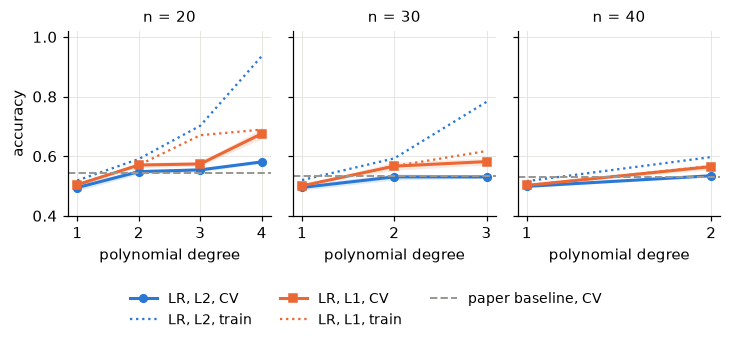

saved exp_figures/fig_lr_degree.pdf


In [7]:
tab, edge = [], 0
for n in NS:
    r0 = CV.where(n=n, family="paper")[0]
    tab.append([n, NAME["paper"], "2 (raw X)", f"{r0['mean']:.3f} ± {r0['sd']:.3f}", f"{r0['train']:.3f}", "", ""])
    for d in range(1, G["MAX_DEG"][n] + 1):
        for fam in ("lr_l2", "lr_l1"):
            rs = [r for r in CV.where(n=n, family=fam, sub=f"deg{d}")]
            b = max(rs, key=lambda r: r["mean"]); Cs = sorted(r["params"]["C"] for r in rs); e = b["params"]["C"] in (Cs[0], Cs[-1]); edge += e
            nnz = np.mean([p["nnz"] for p in b["post"]]); nf = b["post"][0]["n_feats"]
            tab.append([n, NAME[fam], d, f"{b['mean']:.3f} ± {b['sd']:.3f}", f"{b['train']:.3f}", f"C = {b['params']['C']:g}" + (" (edge of grid)" if e else ""), f"{nnz:.0f} / {nf}"])
display(Markdown(md_table(["n", "model", "degree", "CV accuracy (mean ± sd over folds)", "train accuracy", "best C", "nonzero weights / features"], tab)))
print(f"{edge} of {len([t for t in tab if t[1] != NAME['paper']])} (degree, penalty) cells chose a C on the edge of its grid; if many, widen C_L1 / C_L2.")

fig, axes = plt.subplots(1, 3, figsize=(6.75, 2.6), sharey=True)
for ax, n in zip(axes, NS):
    degs = list(range(1, G["MAX_DEG"][n] + 1))
    for fam in ("lr_l2", "lr_l1"):
        bs = [max(CV.where(n=n, family=fam, sub=f"deg{d}"), key=lambda r: r["mean"]) for d in degs]
        m, s = np.array([b["mean"] for b in bs]), np.array([b["sd"] for b in bs])
        ax.plot(degs, m, marker=MK[fam], color=COL[fam], label=f"{NAME[fam]}, CV"); ax.fill_between(degs, m - s, m + s, color=COL[fam], alpha=0.15, lw=0)
        ax.plot(degs, [b["train"] for b in bs], ls=":", color=COL[fam], lw=1.5, label=f"{NAME[fam]}, train")
    ax.axhline(CV.where(n=n, family="paper")[0]["mean"], color=GRAY, ls="--", lw=1.3, label="paper baseline, CV")
    ax.set_title(f"n = {n}"); ax.set_xlabel("polynomial degree"); ax.set_xticks(degs); ax.set_ylim(0.40, 1.02)
axes[0].set_ylabel("accuracy")
h, l = axes[0].get_legend_handles_labels(); fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3)
fig.tight_layout(); savefig(fig, "fig_lr_degree")

## 3. Trees, forests, gradient boosting, and a small K-means baseline

**Trees and boosting.** The paper only tried polynomials. A single tree needs a first split with some signal, and for a parity-like label no single bit carries any, so it may struggle; a forest that looks at many features per split gives each tree a chance to find a useful combination. Depth, leaf size and features per split are tuned by the same CV.

**K-means (a deliberately small baseline).** K-means is unsupervised, so it can only help if the label is, to a useful degree, a function of *which region of bit space* a row falls in. We fit K-means on the training folds' bits for a few values of k, and use it in two ways: each cluster predicts the majority label of the training rows assigned to it; or the one-hot cluster assignment is the only input to a logistic regression. All fitting and label assignment happens on the training folds only. If both stay near chance this is a finding in itself (the structure is not "nearby rows share labels") and it is not expanded.

In [8]:
for n in NS:
    for d in G["DT_DEPTH"]:
        for l in G["DT_LEAF"]:
            cv_config(n, "TREE", "dtree", "all", "dtree", dict(max_depth=d, msl=l))
    for f in G["RF_MAXF"]:
        for l in G["RF_LEAF"]:
            cv_config(n, "TREE", "rf", "all", "rf", dict(max_features=f, msl=l))
    for d in G["HGB_DEPTH"]:
        cv_config(n, "TREE", "hgb", "all", "hgb", dict(max_depth=d))
    for k in G["KM_K"]:
        cv_config(n, "KM", "kmeans_major", "all", "kmeans_major", dict(k=k))
        cv_config(n, "KM", "kmeans_onehot", "all", "kmeans_onehot", dict(k=k))

TREE|20|dtree|all|dtree|{"max_depth": 2, "msl": 1}             0.498 ± 0.009  (0.1s)
TREE|20|dtree|all|dtree|{"max_depth": 2, "msl": 10}            0.498 ± 0.009  (0.1s)
TREE|20|dtree|all|dtree|{"max_depth": 4, "msl": 1}             0.531 ± 0.022  (0.1s)
TREE|20|dtree|all|dtree|{"max_depth": 4, "msl": 10}            0.531 ± 0.022  (0.1s)
TREE|20|dtree|all|dtree|{"max_depth": 6, "msl": 1}             0.569 ± 0.056  (0.1s)
TREE|20|dtree|all|dtree|{"max_depth": 6, "msl": 10}            0.569 ± 0.056  (0.1s)
TREE|20|dtree|all|dtree|{"max_depth": 8, "msl": 1}             0.623 ± 0.087  (0.1s)
TREE|20|dtree|all|dtree|{"max_depth": 8, "msl": 10}            0.623 ± 0.087  (0.1s)
TREE|20|dtree|all|dtree|{"max_depth": 12, "msl": 1}            0.687 ± 0.083  (0.2s)
TREE|20|dtree|all|dtree|{"max_depth": 12, "msl": 10}           0.652 ± 0.094  (0.1s)
TREE|20|dtree|all|dtree|{"max_depth": null, "msl": 1}          0.690 ± 0.079  (0.2s)
TREE|20|dtree|all|dtree|{"max_depth": null, "msl": 10}         0.

## 4. MLP from scratch

**Question.** Does a ReLU network trained from scratch on the bits learn the label, and how much does width and depth matter?

**Design.** scikit-learn MLP, Adam, early stopping on a 10 % hold-out *inside each training fold*, long patience (50 epochs, up to 400) because for parity-like targets training can sit on a flat plateau at 50 % before the loss moves. Two sizes and one weight decay; no wider search, because every configuration is five fits. This is the "MLP from scratch" arm; it stands in for KryptoNet-sized networks (optional, §1).

In [9]:
MLP_GRID = [dict(h=h, alpha=a) for h in G["MLP_H"] for a in G["MLP_ALPHA"]]
for n in NS:
    for p in MLP_GRID:
        cv_config(n, "MLP", "mlp", "all", "mlp", p, post=lambda m: dict(epochs=int(m.n_iter_)))

MLP|20|mlp|all|mlp|{"alpha": 0.01, "h": [128, 128]}            0.851 ± 0.023  (146.5s)
MLP|20|mlp|all|mlp|{"alpha": 0.01, "h": [256, 256, 256]}       0.886 ± 0.014  (455.2s)
MLP|30|mlp|all|mlp|{"alpha": 0.01, "h": [128, 128]}            0.660 ± 0.025  (160.5s)
MLP|30|mlp|all|mlp|{"alpha": 0.01, "h": [256, 256, 256]}       0.854 ± 0.057  (2111.8s)
MLP|40|mlp|all|mlp|{"alpha": 0.01, "h": [128, 128]}            0.864 ± 0.041  (768.4s)
MLP|40|mlp|all|mlp|{"alpha": 0.01, "h": [256, 256, 256]}       0.936 ± 0.004  (9094.3s)


| n | model (best setting by CV mean) | CV accuracy (mean ± sd over folds) | train accuracy | setting |
|---|---|---|---|---|
| 20 | paper baseline (quadratic LR), degree 2 | 0.544 ± 0.010 | 0.592 | {"deg": 2, "C": 0.85} |
| 20 | LR, L2, degree 4 | 0.581 ± 0.004 | 0.936 | {"deg": 4, "C": 0.001} |
| 20 | LR, L1, degree 4 | 0.675 ± 0.017 | 0.689 | {"deg": 4, "C": 0.01} |
| 20 | decision tree | 0.690 ± 0.079 | 1.000 | {"max_depth": null, "msl": 1} |
| 20 | random forest | 0.824 ± 0.023 | 0.981 | {"max_features": 1.0, "msl": 5} |
| 20 | gradient boosting | 0.749 ± 0.023 | 0.881 | {"max_depth": null} |
| 20 | K-means, cluster majority | 0.506 ± 0.007 | 0.512 | {"k": 8} |
| 20 | K-means, one-hot + LR | 0.506 ± 0.007 | 0.512 | {"k": 8} |
| 20 | MLP | 0.886 ± 0.014 | 0.989 | {"h": [256, 256, 256], "alpha": 0.01} |
| 30 | paper baseline (quadratic LR), degree 2 | 0.532 ± 0.011 | 0.596 | {"deg": 2, "C": 0.85} |
| 30 | LR, L2, degree 2 | 0.531 ± 0.010 | 0.593 | {"deg": 2, "C": 0.01} |
| 30 | LR, L1, degree 3 | 0.582 ± 0.011 | 0.617 | {"deg": 3, "C": 0.01} |
| 30 | decision tree | 0.573 ± 0.089 | 0.923 | {"max_depth": 12, "msl": 1} |
| 30 | random forest | 0.784 ± 0.028 | 0.999 | {"max_features": 1.0, "msl": 5} |
| 30 | gradient boosting | 0.695 ± 0.045 | 0.853 | {"max_depth": null} |
| 30 | K-means, cluster majority | 0.504 ± 0.010 | 0.526 | {"k": 32} |
| 30 | K-means, one-hot + LR | 0.505 ± 0.010 | 0.526 | {"k": 32} |
| 30 | MLP | 0.854 ± 0.057 | 0.980 | {"h": [256, 256, 256], "alpha": 0.01} |
| 40 | paper baseline (quadratic LR), degree 2 | 0.531 ± 0.003 | 0.600 | {"deg": 2, "C": 0.85} |
| 40 | LR, L2, degree 2 | 0.534 ± 0.004 | 0.597 | {"deg": 2, "C": 0.01} |
| 40 | LR, L1, degree 2 | 0.565 ± 0.011 | 0.567 | {"deg": 2, "C": 0.01} |
| 40 | decision tree | 0.528 ± 0.028 | 0.875 | {"max_depth": 12, "msl": 1} |
| 40 | random forest | 0.786 ± 0.024 | 1.000 | {"max_features": 1.0, "msl": 5} |
| 40 | gradient boosting | 0.674 ± 0.053 | 0.775 | {"max_depth": null} |
| 40 | K-means, cluster majority | 0.506 ± 0.006 | 0.508 | {"k": 8} |
| 40 | K-means, one-hot + LR | 0.506 ± 0.006 | 0.508 | {"k": 8} |
| 40 | MLP | 0.936 ± 0.004 | 0.994 | {"h": [256, 256, 256], "alpha": 0.01} |

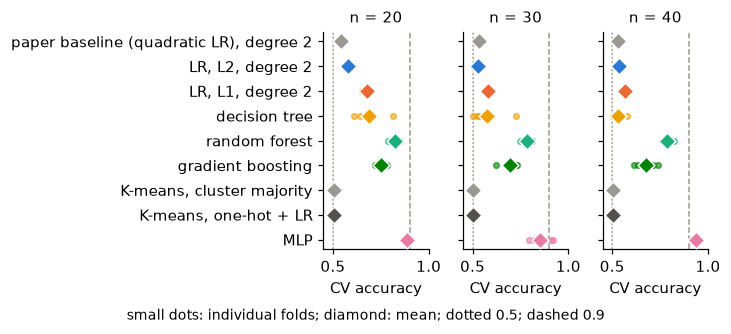

saved exp_figures/fig_generic.pdf


In [10]:
# ---- generic models on all bits: best setting of each family (CV)
GENERIC = ("paper", "lr_l2", "lr_l1", "dtree", "rf", "hgb", "kmeans_major", "kmeans_onehot", "mlp")


def best_generic(n):
    out = []
    for fam in GENERIC:
        gs = [g for g in groups(n) if g["key"][0] == fam and g["key"][1] == "all"]
        if gs:
            out.append(max(gs, key=lambda g: g["best"]["mean"]))
    return out


def top_generic(n):
    return max((g for g in best_generic(n) if g["key"][0] != "paper"), key=lambda g: g["best"]["mean"])    # the paper baseline is a reference, not a candidate


tab = []
for n in NS:
    for g in best_generic(n):
        b = g["best"]; tab.append([n, kname(g["key"]), f"{b['mean']:.3f} ± {b['sd']:.3f}", f"{b['train']:.3f}", json.dumps(b["params"])])
display(Markdown(md_table(["n", "model (best setting by CV mean)", "CV accuracy (mean ± sd over folds)", "train accuracy", "setting"], tab)))

fig, axes = plt.subplots(1, 3, figsize=(6.75, 2.9), sharey=True)
for ax, n in zip(axes, NS):
    gs = best_generic(n)
    for i, g in enumerate(gs):
        fam = g["key"][0]; f = g["best"]["folds"]
        ax.scatter(f, [i] * len(f), s=14, color=COL[fam], alpha=0.6, zorder=3, marker="o")
        ax.scatter([g["best"]["mean"]], [i], s=60, color=COL[fam], marker="D", edgecolor="white", zorder=4)
    ax.axvline(0.5, color=GRAY, ls=":", lw=1); ax.axvline(0.9, color=GRAY, ls="--", lw=1)
    ax.set_yticks(range(len(gs))); ax.set_yticklabels([kname(g["key"]) for g in gs]); ax.tick_params(labelleft=(n == NS[0])); ax.grid(axis="y", alpha=0)
    ax.set_xlim(0.45, 1.0); ax.set_title(f"n = {n}"); ax.set_xlabel("CV accuracy"); ax.invert_yaxis()
fig.text(0.5, -0.02, "small dots: individual folds; diamond: mean; dotted 0.5; dashed 0.9", ha="center", fontsize=9)
fig.tight_layout(); savefig(fig, "fig_generic")

## 5. The bit selector: what it computes, what it assumes, and whether to trust it

Sections 6 and onward use a feature-selection step before the classifier. This section states exactly what that step is, separates what holds without assumptions from what needs assumptions, tests the assumptions on the actual inputs, and validates the step on synthetic data where the right answer is known. **§6 is only meaningful if this section's results are acceptable; read them first.**

### 5.1 What it computes

Write $s = 2y - 1 \in \{\pm 1\}$ and let $b_j \in \{\pm 1\}$ be the bits (the sign of the input).

1. **Gate.** Find the pair $(a, b)$ maximising $|\hat E[\,s\, b_a b_b\,]|$ over all $\binom n2$ pairs.
2. **Scan.** For every set $T$ of 1 to 4 other bits, compute $c(T) = \hat E[\,s\, b_a b_b \prod_{j \in T} b_j\,]$, the sample correlation of the label with the product of the bits in $T \cup \{a, b\}$ (orders 3 to 6). Keep those with $|c(T)| > 4/\sqrt N$, four standard errors of an average of $N$ values of $\pm 1$.
3. **Mass.** $\text{mass}(j) = \sum_{T \ni j} c(T)^2$ over the scanned coefficients that a rule counts (the gate has no mass of its own). Scanned coefficients above 3 standard errors are stored; each rule below decides which of them count and which bits to keep. **Three selection rules are compared**, all from the same scan:
   * **4-sigma rule.** Counts coefficients above $4/\sqrt N$ and keeps the gate plus every bit with mass $> 0.02$ (at most 14 bits). This is the rule used in our exploratory runs.
   * **Bonferroni rule (a conservative statistical reference).** Counts only coefficients whose $|c|\sqrt N$ exceeds the Bonferroni bound for $m_{\text{total}} = \binom n2 + \sum_{k=1}^{4} \binom{n-2}{k}$ tests at family-wise level 0.05, **which includes the $\binom n2$ pair tests that chose the gate**, and keeps the gate plus every bit in a surviving coefficient. If the gate pair itself does not pass, nothing is selected and the second stage predicts the majority class.
   * **Top-k rule.** Counts coefficients above 3 standard errors, ranks the bits by mass, and keeps the gate plus the highest-ranked bits so that $k$ bits are kept in all ($k$ includes the 2 gate bits; fewer if fewer bits have any mass). **$k$ is chosen by an inner cross-validation inside each training fold** (3 folds of that training set, $k \in \{4, 6, 8, 10, 12, 14\}$, forest fixed at the outer configuration, ties to the smaller $k$), so the held-out outer fold never influences $k$ either. Statistical significance only informs this rule (through the 3-sigma floor); it does not decide it.

It runs inside every training fold, on that fold's training rows only, so the held-out fold never influences which bits are chosen. (The scan is done with matrix products: all coefficients of a given order come from a few large matrix multiplications, and a test below checks it against a plain loop over subsets.)

### 5.1b Which thresholds have a formal guarantee, and which are empirical heuristics

| ingredient | status | what the guarantee is, or why it is a heuristic |
|---|---|---|
| Bonferroni bound on $\lvert c \rvert \sqrt N$ | **formal, with conditions** | If the labels are independent of the inputs, the chance that *any* of the $m_{\text{total}}$ tested coefficients exceeds the bound is at most 0.05, by a union bound and the normal approximation (a Hoeffding bound makes it non-asymptotic and slightly stricter). It controls false positives only: it says nothing about recall, about predictive accuracy, or (without independent uniform bits) about relevance. The union bound treats the gate search as $\binom n2$ extra tests; that the scan statistics are not distorted by choosing the gate on the same labels is argued from orthogonality and **checked empirically in §5.5, not proved** |
| 4 standard errors, per test | **formal per test, not per family** | Each single coefficient exceeds it with probability about $6.3 \times 10^{-5}$ under the null, but over thousands of coefficients false hits are expected (0.26 / 1.5 / 5.3 per scan) |
| mass threshold 0.02, cap of 14 bits, gate always kept | **empirical heuristic** | chosen by us; no guarantee. In effect the mass threshold, not the 4-sigma test, is what keeps false bits out under the null |
| ranking by mass, the 3-sigma floor | **empirical heuristic** | the ranking is a sensible score but has no error guarantee; the floor is a choice that lets weaker signals in at the price of more noise coefficients |
| $k$ in the top-$k$ rule | **tuned by inner CV** | its only guarantee is that of cross-validation: an estimate of out-of-sample accuracy for each $k$ (noisy, and optimistic for the best $k$). It gives no false-positive control |
| the gate (largest pair coefficient) | **empirical heuristic** | there is no guarantee that it is the right pair, or that one exists (cases D, E below) |
| interpretation of mass as Fourier coefficient or influence | **needs independent uniform bits** | checked on the real inputs in §5.4 |

### 5.2 Two different claims, with different assumptions

**(i) A predictive-association screen. No assumption on the inputs.** $c(S)$ is the sample correlation between the label and the $\pm 1$ feature $\prod_{j \in S} b_j$. A large $|c|$ means that feature predicts the label in this sample. If the labels are independent of the inputs (the shuffled-label null), every $c(S)$ has mean 0 and standard error about $1/\sqrt N$ *whatever the distribution of the inputs*, so the false-positive calibration (thresholds, Bonferroni) does not rely on uniform bits. It does rely on the scan statistics not being strongly dependent on the choice of gate, which we test empirically rather than assume (§5.4).

**(ii) Fourier coefficients and partial influence. Needs independent, uniformly distributed $\pm 1$ bits.** If the bits are independent and uniform, the products $\chi_S = \prod_{j \in S} b_j$ are orthonormal, $c(S)$ estimates the Walsh–Fourier coefficient $\hat f(S)$ of the label function, bit $j$ has zero influence exactly when all coefficients containing it vanish, and mass$(j)$ is a lower bound on its influence. If the bits are biased or correlated the $\chi_S$ are no longer orthogonal: for example with $s = b_1 b_2$ and a bit $b_k$ of mean $\mu$, $\hat E[s\, b_1 b_2 b_k] = \mu$, so an irrelevant bit can look relevant and mass is no longer an influence. The same happens with dependence among irrelevant bits alone: if a set $S$ of irrelevant bits has $E[\chi_S] \neq 0$, then $c(S \cup \text{gate}) \approx E[\chi_S]\, c(\text{gate})$, so the gate's own coefficient leaks into $S$. The leak is at most $|E[\chi_S]| \cdot |c(\text{gate})|$, which is why a small undetected bias in the real inputs would be harmless. §5.3 checks the assumption on the real inputs; §5.4 shows what breaks when it fails.

### 5.3 What it can and cannot detect

* **The gate step needs a pairwise (order-2) coefficient.** The gate is the pair with the largest $|\hat E[s\, b_a b_b]|$. If the label function has terms containing a pair of bits but no term equal to that pair, for example $s = b_a b_b \cdot \text{sign}(\ldots\text{other bits}\ldots)$ with the sign term averaging to about 0, every pairwise coefficient is about 0, the gate is noise, and the scan returns noise (case E below). The same happens for a pure parity (case D).
* **Only terms that contain the gate pair** are scanned. A part of the label function that does not involve both gate bits is invisible (case B).
* **Order.** Gate + at most 4 bits: monomials of order 3 to 6 containing the gate (order 2 is the gate itself). Order 7 and higher is invisible. A bit that appears only in such terms is missed.
* **Size.** A coefficient is detectable only if it is above $4/\sqrt N$ (0.046, 0.035, 0.028 at the fold-train sizes of n = 20, 30, 40); a Bonferroni threshold is higher (about 4.4 to 5.0 standard errors). Many small terms can be missed together.
* **Arbitrary choices.** The mass threshold 0.02 and the cap of 14 bits are not derived from anything.
* **Multiple testing.** The 4-sigma rule has no family-wise control: under pure noise it expects $0.26 / 1.5 / 5.3$ spurious coefficients per scan at n = 20 / 30 / 40 ($m$ = 4,047 / 24,157 / 82,992 tests, each exceeding 4 sd with probability $6.3 \times 10^{-5}$). One spurious coefficient adds at least $16/N$ to the mass of its bits (0.0021, 0.0013, 0.0008), so about 10 / 16 / 26 spurious coefficients on one bit would be needed to pass 0.02 at n = 20 / 30 / 40; the 4-sigma rule is therefore protected by the mass threshold, not by the test itself, and it always keeps the gate. The Bonferroni rule controls the family-wise error by a union bound over all tests above, including the gate search.

In [11]:
# ------------------------------------------------------------------------------ the selector
@lru_cache(None)
def _triu(m):
    return np.triu_indices(m, 1)


def scan_core(R, z, maxdeg):
    # mean(z * prod(R[:, T])) for EVERY subset T of the columns of R with |T| = 1..maxdeg, via a few matrix products
    # (maxdeg <= 4). Returns {k: (subsets as an array of column indices, coefficients)}.
    N, m = R.shape; R = np.ascontiguousarray(R, dtype=np.float32); z = np.asarray(z, dtype=np.float32)
    assert maxdeg <= 4
    out = {1: (np.arange(m)[:, None], (R.T @ z) / N)}
    if maxdeg >= 2:
        M = (R * z[:, None]).T @ R / N; iu = _triu(m)
        out[2] = (np.stack(iu, 1), M[iu])
    if maxdeg >= 3:
        cs, vs = [], []
        for i in range(m - 2):
            Rs = R[:, i + 1:]; M = (Rs * (z * R[:, i])[:, None]).T @ Rs / N; a, b = _triu(m - i - 1)
            cs.append(np.stack([np.full(len(a), i), a + i + 1, b + i + 1], 1)); vs.append(M[a, b])
        out[3] = (np.concatenate(cs), np.concatenate(vs))
    if maxdeg >= 4:
        cs, vs = [], []
        for i in range(m - 3):
            for j in range(i + 1, m - 2):
                Rs = R[:, j + 1:]; M = (Rs * (z * R[:, i] * R[:, j])[:, None]).T @ Rs / N; a, b = _triu(m - j - 1)
                cs.append(np.stack([np.full(len(a), i), np.full(len(a), j), a + j + 1, b + j + 1], 1)); vs.append(M[a, b])
        out[4] = (np.concatenate(cs), np.concatenate(vs))
    return out


Z_FLOOR = 3.0          # coefficients above this many standard errors are stored; the rules apply their own, stricter or equal, cut


def scan_bits(B, y, maxdeg=4):
    # steps 1 and 2 of 5.1. Returns everything the selection rules need: the gate, its coefficient, and every scanned
    # coefficient above Z_FLOOR standard errors. No selection rule is applied here.
    N, n = B.shape; s = (2.0 * y - 1).astype(np.float32)
    C = (B * s[:, None]).T @ B / N; np.fill_diagonal(C, 0.0)
    a, b = np.unravel_index(np.argmax(np.abs(C)), C.shape)
    pair = (int(min(a, b)), int(max(a, b)))
    rest = np.array([i for i in range(n) if i not in pair])
    res = scan_core(B[:, rest], s * B[:, pair[0]] * B[:, pair[1]], maxdeg)
    thr = Z_FLOOR / np.sqrt(N); hits = []
    for k, (cm, cf) in res.items():
        for i in np.where(np.abs(cf) > thr)[0]:
            hits.append([[int(rest[q]) for q in cm[i]], float(cf[i])])
    return dict(pair=list(pair), gate_coef=float(C[a, b]), hits=hits, N=int(N), n=int(n))


def m_total(n, maxdeg=4):
    return comb(n, 2) + sum(comb(n - 2, k) for k in range(1, maxdeg + 1))     # gate search + scan


def z_bonf(m, alpha=0.05):
    return float(stats.norm.isf(alpha / (2 * m)))                              # two-sided Bonferroni bound, in standard errors


def choose_bits(res, rule="orig", max_bits=14, mass_thr=0.02, alpha=0.05, k=None):
    # 'orig': the 4-sigma rule; 'bonf': the Bonferroni rule; 'topk': the k highest-mass bits (k counts the 2 gate bits)
    N, n, pair, hits = res["N"], res["n"], res["pair"], res["hits"]; zb = z_bonf(m_total(n), alpha); sq = np.sqrt(N); gate_z = abs(res["gate_coef"]) * sq
    if rule == "bonf":
        if gate_z < zb:
            return dict(bits=[], pair=pair, mass=[0.0] * n, zb=zb, gate_z=gate_z)
        hits = [h for h in hits if abs(h[1]) * sq >= zb]
    elif rule == "orig":
        hits = [h for h in hits if abs(h[1]) > 4.0 / sq]
    mass = np.zeros(n)
    for T, c in hits:
        for t in T:
            mass[t] += c * c
    keep = mass > (mass_thr if rule == "orig" else 0.0)
    ranked = [int(i) for i in np.argsort(-mass) if keep[i] and i not in pair]
    cap = max_bits if rule != "topk" else min(int(k), max_bits)
    return dict(bits=sorted(pair + ranked[: max(cap - 2, 0)]), pair=pair, mass=[round(float(v), 5) for v in mass], zb=zb, gate_z=gate_z)


_SCAN_PATH = f"{OUT}/scan_cache.json"
_SCAN = json.load(open(_SCAN_PATH)) if os.path.exists(_SCAN_PATH) else {}


def get_scan(B, y):
    # scan_bits with an on-disk cache keyed by the content of (B, y): the same training rows are never scanned twice
    key = hashlib.md5(np.ascontiguousarray(B).tobytes() + y.astype(np.int8).tobytes()).hexdigest()[:16] + f"|{B.shape[0]}x{B.shape[1]}|z{Z_FLOOR}"
    if key not in _SCAN:
        _SCAN[key] = scan_bits(B, y)
        json.dump(_SCAN, open(_SCAN_PATH, "w"))
    return _SCAN[key]


class BitModel:
    # wraps any estimator: scan + select on the rows it is FITTED on, then fit the estimator on those columns only.
    # If the rule selects nothing, it predicts the training majority class.
    def __init__(self, base, rule="orig"):
        self.base, self.rule = base, rule

    def fit(self, B, y):
        self.scan_ = get_scan(B, y); sel = choose_bits(self.scan_, self.rule)
        self.cols_, self.pair_, self.mass_, self.gate_z_ = sel["bits"], sel["pair"], sel["mass"], sel["gate_z"]
        self.const_ = None if self.cols_ else int(y.mean() >= 0.5)
        if self.cols_:
            self.base.fit(B[:, self.cols_], y)
        return self

    def predict(self, B):
        return np.full(len(B), self.const_) if self.const_ is not None else self.base.predict(B[:, self.cols_])


class TopKModel:
    # top-k rule: scan the rows it is fitted on; choose k by an INNER cross-validation on those rows (inner scans and inner
    # fits use only inner-training rows); refit on all of them with the chosen k. make_base() builds a fresh second-stage classifier.
    def __init__(self, base, make_base):
        self.base, self.make_base = base, make_base

    def fit(self, B, y):
        self.scan_ = get_scan(B, y); ks = G["KS_TOPK"]; sc = {k: [] for k in ks}
        for a, b in StratifiedKFold(G["INNER_K"], shuffle=True, random_state=SEED).split(B, y):
            res = get_scan(B[a], y[a])
            for k in ks:
                cols = choose_bits(res, "topk", k=k)["bits"]
                sc[k].append(acc(self.make_base().fit(B[a][:, cols], y[a]), B[b][:, cols], y[b]))
        self.k_ = max(ks, key=lambda k: (round(float(np.mean(sc[k])), 9), -k)); self.inner_ = {int(k): round(float(np.mean(v)), 4) for k, v in sc.items()}
        sel = choose_bits(self.scan_, "topk", k=self.k_)
        self.cols_, self.pair_, self.mass_, self.gate_z_ = sel["bits"], sel["pair"], sel["mass"], sel["gate_z"]
        self.base.fit(B[:, self.cols_], y)
        return self

    def predict(self, B):
        return self.base.predict(B[:, self.cols_])


# ---- tests
def _brute_bits(B, y, maxdeg=4, mass_thr=0.02, max_bits=14):
    # the original loop over all subsets (the version of the selector we first showed); used only to test scan_bits
    N, n = B.shape; s = 2.0 * y - 1; C = (B * s[:, None]).T @ B / N; np.fill_diagonal(C, 0.0)
    a, b = np.unravel_index(np.argmax(np.abs(C)), C.shape); pair = (int(min(a, b)), int(max(a, b)))
    z = (s * B[:, pair[0]] * B[:, pair[1]]).astype(np.float32); rest = [i for i in range(n) if i not in pair]; mass, thr = np.zeros(n), 4.0 / np.sqrt(N)
    for k in range(1, maxdeg + 1):
        for c in itertools.combinations(rest, k):
            coef = float((z * np.prod(B[:, list(c)], axis=1)).mean())
            if abs(coef) > thr:
                for t in c:
                    mass[t] += coef ** 2
    ranked = [int(i) for i in np.argsort(-mass) if mass[i] > mass_thr and i not in pair]
    return sorted(list(pair) + ranked[: max_bits - 2]), mass


_rng = np.random.default_rng(1); _n, _N = 12, 700
_B = _rng.choice([-1.0, 1.0], (_N, _n)).astype(np.float32)
_f = _B[:, 0] * _B[:, 1] * _B[:, 2] + 0.8 * _B[:, 0] * _B[:, 1] * _B[:, 5] * _B[:, 6] + 0.6 * _B[:, 0] * _B[:, 1]
_y = ((_f + _rng.normal(0, 0.3, _N)) > 0).astype(int)
_bits_ref, _mass_ref = _brute_bits(_B, _y)
_res = scan_bits(_B, _y)
assert choose_bits(_res, "orig")["bits"] == _bits_ref, "fast scan disagrees with the plain loop"
assert np.abs(np.array(choose_bits(_res, "orig")["mass"]) - _mass_ref).max() < 1e-4, "mass differs from the plain loop"
assert set(_res["pair"]) == {0, 1} and {0, 1, 2, 5, 6} <= set(_bits_ref), "planted gate terms not found"
assert {0, 1, 2, 5, 6} <= set(choose_bits(_res, "topk", k=7)["bits"]) and len(choose_bits(_res, "topk", k=7)["bits"]) <= 7 and len(choose_bits(_res, "topk", k=4)["bits"]) == 4, "top-k rule"
_G0 = dict(G); G["KS_TOPK"], G["INNER_K"] = [4, 6], 2
_tk = TopKModel(Lookup(), Lookup).fit(_B, _y); assert _tk.k_ in (4, 6) and set(_tk.cols_) >= set(_res["pair"]) and _tk.predict(_B).shape == (_N,)
G.update(_G0)
# a label that is a function of one pair only: exactly that pair is selected, by both rules
_B2 = np.random.default_rng(2).choice([-1.0, 1.0], (7680, 20)).astype(np.float32)
_y2 = ((_B2[:, 3] * _B2[:, 5] > 0) ^ (np.random.default_rng(3).random(7680) < 0.03)).astype(int)
_r2 = scan_bits(_B2, _y2)
assert _r2["pair"] == [3, 5] and choose_bits(_r2, "bonf")["bits"] == [3, 5] and choose_bits(_r2, "orig")["bits"] == [3, 5]
# the Bonferroni rule selects nothing when the labels are noise
_r3 = scan_bits(_B2, np.random.default_rng(4).integers(0, 2, 7680))
assert choose_bits(_r3, "bonf")["bits"] == [], "Bonferroni rule should find nothing in pure noise"
print("selector tests passed; Bonferroni bounds (standard errors) for n = 20 / 30 / 40:", [round(z_bonf(m_total(n)), 2) for n in NS],
      "; tests m_total:", [m_total(n) for n in NS])

selector tests passed; Bonferroni bounds (standard errors) for n = 20 / 30 / 40: [4.38, 4.75, 4.99] ; tests m_total: [4237, 24592, 83772]


### 5.4 Is the independent-uniform-bits assumption supported by the actual inputs?

This uses the **inputs only** (no labels), on the dev rows, with the hidden-set inputs as an independent second sample. If the bits are independent and uniform, then for every subset $S$ the product $\prod_{j \in S} b_j$ has mean 0 and standard deviation 1, so $z_S = \sqrt N\, \bar{\chi}_S$ is approximately standard normal. We compute $z_S$ for **every** subset of up to 4 bits (the orders the selector uses) and compare the largest with the Bonferroni bound for that many tests (family-wise level 0.05). We also compare the Hamming-weight distribution with Binomial$(n, \tfrac12)$, and the dev rows with the hidden rows. Any subset beyond the bound is re-measured on the hidden rows, where a real effect should reappear.

**What this can and cannot show.** It can detect a bias or dependence of about $4/\sqrt N$ (0.03 to 0.05) or more, in subsets of up to 4 bits. It cannot rule out smaller deviations, nor dependence among 5 or more bits at once.

In [12]:
def input_check(B, Bh=None, X=None):
    # inputs only. B: dev rows' bits (+-1); Bh: hidden rows' bits (second, independent sample); X: noisy inputs for the noise check
    N, n = B.shape; out = {}
    res = scan_core(B, np.ones(N, np.float32), 4)
    zs = {k: cf * np.sqrt(N) for k, (cm, cf) in res.items()}
    m_all = sum(len(z) for z in zs.values()); out["zb"] = z_bonf(m_all)
    out["maxz"] = {k: float(np.abs(z).max()) for k, z in zs.items()}
    out["sd_z"] = {k: float(z.std()) for k, z in zs.items()}
    out["ks_p"] = {k: float(stats.kstest(z, "norm").pvalue) for k, z in zs.items() if k >= 2}
    out["max_abs_mean"] = float(np.abs(B.mean(0)).max())
    out["marg_chi2_p"] = float(stats.chi2.sf((zs[1] ** 2).sum(), n))
    w = (B > 0).sum(1); exp = stats.binom.pmf(np.arange(n + 1), n, 0.5) * N; obs = np.bincount(w, minlength=n + 1); ok = exp > 5
    out["hamming_p"] = float(stats.chi2.sf(((obs[ok] - exp[ok]) ** 2 / exp[ok]).sum(), ok.sum() - 1))
    flagged = []
    for k, (cm, cf) in res.items():
        for i in np.where(np.abs(zs[k]) > out["zb"])[0]:
            flagged.append((cm[i].tolist(), float(zs[k][i])))
    flagged.sort(key=lambda t: -abs(t[1])); out["flagged"] = flagged[:5]; out["n_flagged"] = len(flagged)
    if Bh is not None:
        Nh = len(Bh)
        out["hid_vs_dev_marg_maxz"] = float(np.abs((B.mean(0) - Bh.mean(0)) / np.sqrt(1 / N + 1 / Nh)).max())
        iu = np.triu_indices(n, 1)
        out["hid_vs_dev_pair_maxz"] = float(np.abs(((B.T @ B / N) - (Bh.T @ Bh / Nh))[iu] / np.sqrt(1 / N + 1 / Nh)).max())
        out["flagged_replication"] = [(T, z, float(np.prod(Bh[:, T], axis=1).mean() * np.sqrt(Nh))) for T, z in out["flagged"]]
    if X is not None:
        r = X - B; out["noise_sd"] = float(r.std()); out["noise_kurt"] = float(stats.kurtosis(r.ravel()))
    return out


def input_flag(B):
    # cheap pre-flight diagnostic (orders 1 and 2 only): does any bias or pairwise dependence exceed its Bonferroni bound?
    N, n = B.shape; res = scan_core(B, np.ones(N, np.float32), 2); zb = z_bonf(n + comb(n, 2))
    return bool(max(np.abs(res[1][1]).max(), np.abs(res[2][1]).max()) * np.sqrt(N) > zb)


rows, details = [], []
for n in NS:
    X, B, y = load(n)
    Bh = np.where(np.load(f"{DATA}/hidden-kryptonite-{n}-X.npy") > 0, 1.0, -1.0).astype(np.float32)
    r = input_check(B[DEV[n]], Bh, X[DEV[n]])                                   # dev rows only: the locked rows are not used
    floor = 4 / np.sqrt(FOLD_TRAIN[n])
    rows.append([n, len(DEV[n]), f"{r['noise_sd']:.3f} (excess kurtosis {r['noise_kurt']:+.2f})", f"{r['max_abs_mean']:.3f} (selector floor {floor:.3f})",
                 " / ".join(f"{r['maxz'][k]:.1f}" for k in (1, 2, 3, 4)), f"{r['zb']:.2f}", f"{r['sd_z'][2]:.2f} / {r['sd_z'][3]:.2f} / {r['sd_z'][4]:.2f}",
                 f"{r['marg_chi2_p']:.2f} / {r['hamming_p']:.2f}", f"{r['hid_vs_dev_marg_maxz']:.1f} / {r['hid_vs_dev_pair_maxz']:.1f}", r["n_flagged"]])
    if r["n_flagged"]:
        details.append((n, r))
display(Markdown(md_table(["n", "dev rows", "noise sd", "largest abs. bit mean (vs selector floor 4/sqrt N)", "largest abs. z, orders 1/2/3/4", "Bonferroni bound",
    "sd of z, orders 2/3/4 (1 expected)", "p: bit means / Hamming weight", "hidden vs dev: max abs. z, bit means / pairs", "subsets beyond the bound"], rows)))
for n, r in details:
    print(f"n = {n}: {r['n_flagged']} subset(s) beyond the Bonferroni bound {r['zb']:.2f}. Largest, re-measured on the independent hidden rows (z there; an effect that is real should reappear):")
    for T, z, zh in r["flagged_replication"]:
        print(f"   bits {T}: z(dev) = {z:+.2f}, z(hidden) = {zh:+.2f}")
if not details:
    print("No subset of up to 4 bits is beyond its Bonferroni bound.")

| n | dev rows | noise sd | largest abs. bit mean (vs selector floor 4/sqrt N) | largest abs. z, orders 1/2/3/4 | Bonferroni bound | sd of z, orders 2/3/4 (1 expected) | p: bit means / Hamming weight | hidden vs dev: max abs. z, bit means / pairs | subsets beyond the bound |
|---|---|---|---|---|---|---|---|---|---|
| 20 | 9600 | 0.100 (excess kurtosis +0.00) | 0.031 (selector floor 0.046) | 3.0 / 3.6 / 3.5 / 3.4 | 4.46 | 0.98 / 1.03 / 0.99 | 0.10 / 0.69 | 3.0 / 2.9 | 0 |
| 30 | 16000 | 0.100 (excess kurtosis -0.00) | 0.013 (selector floor 0.035) | 1.6 / 3.2 / 3.8 / 4.3 | 4.80 | 0.99 / 0.99 / 1.00 | 0.89 / 0.84 | 1.9 / 3.1 | 0 |
| 40 | 25600 | 0.100 (excess kurtosis +0.01) | 0.013 (selector floor 0.028) | 2.1 / 3.4 / 4.1 / 4.4 | 5.03 | 1.05 / 1.00 / 1.00 | 0.85 / 0.26 | 2.9 / 4.0 | 0 |

No subset of up to 4 bits is beyond its Bonferroni bound.


### 5.5 Synthetic validation of the whole selector

**Purpose.** To characterise when the selector works and when it does not, not to tune it. Everything below runs the **entire** procedure (gate search, scan, selection rule) at the fold-train size of each n, and reports all three rules. The top-k rule needs a classifier to choose $k$, which is done in §6; here it is shown at two fixed values, $k = 8$ (the true number of relevant bits, so an optimistic oracle) and $k = 12$ (generous).

**Shuffled-label null (real inputs).** Real dev inputs, the training rows of fold 0, labels randomly permuted. Nothing is relevant, so every selected bit is false. We report the false selected bits for each rule (counting the gate), how many scan hits there were against the number expected by chance, how often the Bonferroni rule selects anything at all (it should be at most about 5 %), and how much two null selections overlap (the Jaccard overlap expected from pure noise, which is the baseline against which the real selections' stability in §6 should be read). Because the whole procedure including gate selection is repeated, this measures the effect of choosing the gate on the same labels.

**Planted subsets (independent uniform bits).** Labels are the sign of a sum of $\pm 1$ monomials over a known set of 8 relevant bits, with 4 % of labels flipped. The 4 % and the form of the function are **assumptions made for the test, not findings about the data.**

| case | label function | what it tests |
|---|---|---|
| A | the pair term $b_g b_{g'}$ plus 5 random monomials, each containing that pair plus 1 to 3 other relevant bits | the selector's intended regime |
| B | pair term + 3 monomials containing the pair and 1 to 2 of three bits + 3 monomials over three *other* bits (no gate bit) | bits that appear only in terms without the gate are invisible |
| C | pair term + 3 gate monomials over 2 bits + one monomial of order 8 over all 8 relevant bits | the 4 bits that appear only in the order-8 term are invisible |
| D | parity of 6 bits | no pairwise or low-order correlation: the gate is noise |
| E | 6 monomials (pair + 1 to 3 others) but **no pair term** | the gate step needs an order-2 coefficient (it is found only if the sign nonlinearity happens to create one) |
| A + bias | as A; 6 irrelevant bits have mean +0.1 | non-uniform inputs |
| A + copies | as A; 4 irrelevant bits are copies (90 % agreement) of relevant ones | correlated inputs (informative) |
| A + correlated irrelevant | as A; 4 irrelevant bits are 90 % copies of other irrelevant bits | dependence that carries no label information. Not harmless: if $E[\chi_S] \neq 0$ for a set $S$ of irrelevant bits, then $c(S \cup \text{gate}) \approx E[\chi_S]\, c(\text{gate})$, so $S$ looks relevant |

For each run we record recall (share of relevant bits selected), false bits (selected, not relevant, not a copy of a relevant bit), selected copies, and whether the cheap input diagnostic (`input_flag`, orders 1 and 2) notices the bias or correlation.

In [13]:
CASES = ["A", "B", "C", "D", "E", "A+bias", "A+copies", "A+corrirr"]
CASE_NAME = {"A": "A: gate terms", "B": "B: half avoid gate", "C": "C: order-8 term", "D": "D: parity of 6", "E": "E: no pair term", "A+bias": "A + biased bits", "A+copies": "A + copies of relevant",
             "A+corrirr": "A + correlated irrelevant"}


def planted(rng, n, N, case):
    B = rng.choice([-1.0, 1.0], (N, n)).astype(np.float32)
    perm = [int(i) for i in rng.permutation(n)]; R, rest = perm[:8], perm[8:]; g, others = R[:2], R[2:]
    base = case.split("+")[0]; info = dict(copies=[])
    if case == "A+bias":
        for j in rest[:6]:
            B[:, j] = np.where(rng.random(N) < 0.55, 1.0, -1.0)             # mean +0.1
    if case == "A+copies":
        for r, j in zip(others[:4], rest[:4]):
            B[:, j] = np.where(rng.random(N) < 0.95, B[:, r], -B[:, r]); info["copies"].append(j)       # 95% same-sign draws = 90% correlation
    if case == "A+corrirr":
        for a, b in zip(rest[:4], rest[4:8]):
            B[:, b] = np.where(rng.random(N) < 0.95, B[:, a], -B[:, a])
    pick = lambda pool, lo, hi: [int(v) for v in rng.choice(pool, int(rng.integers(lo, hi + 1)), replace=False)]
    if base == "A":
        terms = [list(g)] + [g + pick(others, 1, 3) for _ in range(5)]
    elif base == "B":                                                        # 3 relevant bits appear only in terms without the gate
        terms = [list(g)] + [g + pick(R[2:5], 1, 2) for _ in range(3)] + [pick(R[5:8], 2, 3) for _ in range(3)]
    elif base == "C":                                                        # 4 relevant bits appear only in the order-8 term
        terms = [list(g)] + [g + pick(R[2:4], 1, 2) for _ in range(3)] + [list(R)]
    elif base == "E":
        terms = [g + pick(others, 1, 3) for _ in range(6)]
    else:                                                                    # D
        terms = [R[:6]]
    f = sum(rng.choice([-1.0, 1.0]) * np.prod(B[:, t], axis=1) for t in terms) + 0.01 * rng.normal(size=N)
    y = ((f > 0) ^ (rng.random(N) < 0.04)).astype(int)
    info["relevant"] = sorted({j for t in terms for j in t})
    return B, y, info


SPECS = {"orig": ("orig", None), "bonf": ("bonf", None), "topk8": ("topk", 8), "topk12": ("topk", 12)}
SPEC_NAME = {"orig": "4-sigma", "bonf": "Bonferroni", "topk8": "top-k, k = 8", "topk12": "top-k, k = 12"}
SPEC_COL = {"orig": ORANGE, "bonf": BLUE, "topk8": VIOLET, "topk12": MAGENTA}


def judge(res, info):
    R, Cp = set(info["relevant"]), set(info["copies"]); out = {}
    for name, (rule, k) in SPECS.items():
        sel = set(choose_bits(res, rule, k=k)["bits"])
        out[name] = dict(recall=len(sel & R) / len(R), false=len(sel - R - Cp), copies=len(sel & Cp), nsel=len(sel), full=int(R <= sel))
    return out


for n in NS:
    N = FOLD_TRAIN[n]
    for ci, case in enumerate(CASES):
        for rep in range(G["SYN_REPS"]):
            def job():
                t0 = time.time(); B, y, info = planted(np.random.default_rng(7919 * rep + 101 * n + ci), n, N, case)
                res = scan_bits(B, y); o = judge(res, info)
                return dict(kind="planted", mean=o["bonf"]["recall"], sd=0.0, secs=round(time.time() - t0, 1), **o, hits=len(res["hits"]),
                            gate_in_relevant=int(set(res["pair"]) <= set(info["relevant"])), flag=input_flag(B), n_relevant=len(info["relevant"]))
            run(SYN, f"syn|{case}|{n}|{rep}", job, quiet=True, exp="SYN", n=n, case=case, rep=rep)
    X, B, y = load(n); tr0 = FOLDS[n][0][0]
    for rep in range(G["NULL_REPS"]):
        def job():
            t0 = time.time(); res = scan_bits(B[tr0], np.random.default_rng(rep).permutation(y[tr0]))
            sels = {name: choose_bits(res, rule, k=k) for name, (rule, k) in SPECS.items()}; sq = np.sqrt(res["N"])
            return dict(kind="null", mean=0.0, sd=0.0, secs=round(time.time() - t0, 1), hits3=len(res["hits"]), hits4=int(sum(abs(h[1]) * sq > 4 for h in res["hits"])),
                        gate_z=sels["orig"]["gate_z"], zb=sels["orig"]["zb"], **{f"bits_{nm}": v["bits"] for nm, v in sels.items()})
        run(SYN, f"null|{n}|{rep}", job, quiet=True, exp="SYN", n=n, case="null", rep=rep)
print("synthetic validation rows:", len(SYN.rows), f"(compute {sum(r['secs'] for r in SYN.rows.values()) / 60:.1f} min)")

synthetic validation rows: 156 (compute 1.9 min)


**Shuffled-label null** (real inputs, labels permuted, the whole selector including gate search; every selected bit is false).

| n | runs | hits above 4 sd: observed / expected by chance | hits above 3 sd: observed / expected | false bits, 4-sigma (incl. 2 gate bits) | false bits, Bonferroni | false bits, top-k = 8 | false bits, top-k = 12 | share of runs where Bonferroni selects anything (nominal <= 0.05) | selection overlap between two null runs, 4-sigma | overlap, top-k = 8 |
|---|---|---|---|---|---|---|---|---|---|---|
| 20 | 20 | 0.3 / 0.3 | 10 / 11 | 2.0 | 0.0 | 8.0 | 12.0 | 0.00 | 0.09 | 0.27 |
| 30 | 20 | 1.6 / 1.5 | 67 / 65 | 2.0 | 0.0 | 8.0 | 12.0 | 0.00 | 0.07 | 0.16 |
| 40 | 20 | 5.0 / 5.3 | 226 / 224 | 2.0 | 0.0 | 8.0 | 12.0 | 0.00 | 0.04 | 0.11 |

**Planted relevant subsets** (mean over 4 repetitions; 8 relevant bits). Each cell: recall / false bits.

| n | case | gate pair inside relevant | 4-sigma | Bonferroni | top-k, k = 8 | top-k, k = 12 | copies selected (4-sigma) | input diagnostic raised |
|---|---|---|---|---|---|---|---|---|
| 20 | A: gate terms | 1.00 | 1.00 / 0.0 | 1.00 / 0.0 | 1.00 / 0.0 | 1.00 / 4.0 | 0.0 | 0.00 |
| 20 | B: half avoid gate | 1.00 | 0.52 / 0.0 | 0.52 / 0.0 | 0.68 / 2.8 | 0.77 / 6.0 | 0.0 | 0.00 |
| 20 | C: order-8 term | 1.00 | 0.75 / 0.0 | 0.75 / 0.0 | 0.78 / 1.8 | 0.88 / 5.0 | 0.0 | 0.00 |
| 20 | D: parity of 6 | 0.00 | 0.08 / 1.5 | 0.00 / 0.0 | 0.37 / 5.8 | 0.58 / 8.5 | 0.0 | 0.25 |
| 20 | E: no pair term | 0.50 | 0.53 / 0.8 | 0.50 / 0.0 | 0.66 / 2.8 | 0.72 / 6.2 | 0.0 | 0.00 |
| 20 | A + biased bits | 1.00 | 1.00 / 0.0 | 1.00 / 1.8 | 1.00 / 0.8 | 1.00 / 4.8 | 0.0 | 1.00 |
| 20 | A + copies of relevant | 1.00 | 1.00 / 0.8 | 1.00 / 0.8 | 0.76 / 0.0 | 1.00 / 0.8 | 4.0 | 1.00 |
| 20 | A + correlated irrelevant | 1.00 | 0.80 / 8.0 | 0.80 / 8.0 | 0.40 / 5.0 | 0.54 / 8.0 | 0.0 | 1.00 |
| 30 | A: gate terms | 1.00 | 1.00 / 0.0 | 1.00 / 0.0 | 1.00 / 0.8 | 1.00 / 4.8 | 0.0 | 0.25 |
| 30 | B: half avoid gate | 1.00 | 0.68 / 0.0 | 0.68 / 0.0 | 0.74 / 2.2 | 0.74 / 6.2 | 0.0 | 0.00 |
| 30 | C: order-8 term | 1.00 | 0.84 / 0.0 | 0.84 / 0.0 | 0.84 / 1.2 | 0.88 / 5.0 | 0.0 | 0.00 |
| 30 | D: parity of 6 | 0.00 | 0.00 / 2.0 | 0.00 / 0.0 | 0.25 / 6.5 | 0.33 / 10.0 | 0.0 | 0.00 |
| 30 | E: no pair term | 0.25 | 0.32 / 1.0 | 0.25 / 0.0 | 0.42 / 5.0 | 0.55 / 8.0 | 0.0 | 0.00 |
| 30 | A + biased bits | 1.00 | 1.00 / 0.0 | 1.00 / 2.8 | 1.00 / 1.2 | 1.00 / 5.2 | 0.0 | 1.00 |
| 30 | A + copies of relevant | 1.00 | 1.00 / 0.0 | 1.00 / 0.0 | 0.71 / 0.0 | 1.00 / 0.2 | 4.0 | 1.00 |
| 30 | A + correlated irrelevant | 1.00 | 0.78 / 8.0 | 0.78 / 8.0 | 0.54 / 4.0 | 0.60 / 7.5 | 0.0 | 1.00 |
| 40 | A: gate terms | 1.00 | 0.96 / 0.0 | 0.96 / 0.0 | 0.96 / 1.5 | 0.96 / 5.5 | 0.0 | 0.00 |
| 40 | B: half avoid gate | 1.00 | 0.64 / 0.0 | 0.64 / 0.0 | 0.67 / 2.8 | 0.71 / 6.5 | 0.0 | 0.00 |
| 40 | C: order-8 term | 1.00 | 0.53 / 0.0 | 0.53 / 0.0 | 0.62 / 3.0 | 0.62 / 7.0 | 0.0 | 0.00 |
| 40 | D: parity of 6 | 0.00 | 0.00 / 2.0 | 0.00 / 0.0 | 0.00 / 8.0 | 0.17 / 11.0 | 0.0 | 0.00 |
| 40 | E: no pair term | 0.00 | 0.00 / 2.0 | 0.00 / 0.0 | 0.19 / 6.5 | 0.29 / 9.8 | 0.0 | 0.00 |
| 40 | A + biased bits | 1.00 | 0.95 / 0.0 | 0.95 / 4.8 | 0.95 / 1.5 | 1.00 / 5.2 | 0.0 | 1.00 |
| 40 | A + copies of relevant | 1.00 | 1.00 / 0.8 | 1.00 / 0.8 | 0.77 / 0.0 | 1.00 / 0.8 | 4.0 | 1.00 |
| 40 | A + correlated irrelevant | 1.00 | 0.87 / 8.0 | 0.87 / 8.0 | 0.68 / 3.2 | 0.68 / 7.2 | 0.0 | 1.00 |

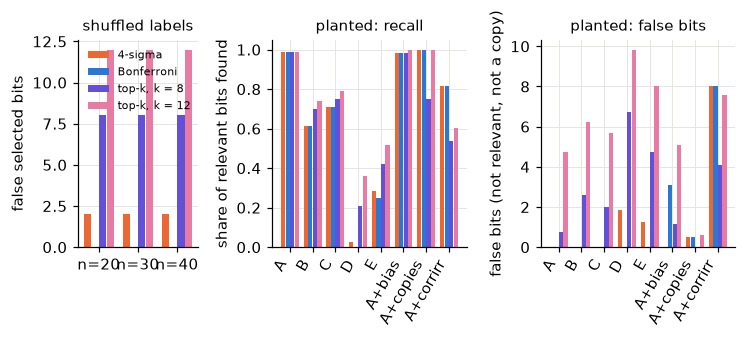

saved exp_figures/fig_selector_validation.pdf
PASS  n=20: Bonferroni rule selects something in 0% of shuffled-label runs (nominal 5%)
PASS  n=20: 4-sigma rule selects 2.0 false bits on shuffled labels (2 = the gate alone)
NOTE  n=20: top-k (k = 8) selects 8.0 false bits on shuffled labels: it fills k whenever any 3-sigma coefficient exists, so it relies on CV, not on significance, to reject noise
PASS  n=20, case A recall: Bonferroni 1.00, 4-sigma 1.00, top-k = 8 1.00
PASS  n=30: Bonferroni rule selects something in 0% of shuffled-label runs (nominal 5%)
PASS  n=30: 4-sigma rule selects 2.0 false bits on shuffled labels (2 = the gate alone)
NOTE  n=30: top-k (k = 8) selects 8.0 false bits on shuffled labels: it fills k whenever any 3-sigma coefficient exists, so it relies on CV, not on significance, to reject noise
PASS  n=30, case A recall: Bonferroni 1.00, 4-sigma 1.00, top-k = 8 1.00
PASS  n=40: Bonferroni rule selects something in 0% of shuffled-label runs (nominal 5%)
PASS  n=40: 

In [14]:
# ---- shuffled-label null (real inputs, whole selector incl. gate search)
def null_jaccard(rs, nm):
    return jaccard_mean([r[f"bits_{nm}"] for r in rs])


def jaccard_mean(sets):
    sets = [set(s) for s in sets]; v = [len(a & b) / max(len(a | b), 1) for a, b in itertools.combinations(sets, 2)]
    return float(np.mean(v)) if v else float("nan")


NULL_STAB = {}                                   # selection overlap between two shuffled-label runs: the 'pure noise' baseline for stability
tab = []
for n in NS:
    rs = SYN.where(n=n, case="null"); m_scan = m_total(n) - comb(n, 2)
    NULL_STAB[n] = {nm: null_jaccard(rs, nm) for nm in SPECS}
    tab.append([n, len(rs), f"{np.mean([r['hits4'] for r in rs]):.1f} / {m_scan * 2 * stats.norm.sf(4):.1f}", f"{np.mean([r['hits3'] for r in rs]):.0f} / {m_scan * 2 * stats.norm.sf(3):.0f}"]
                + [f"{np.mean([len(r[f'bits_{nm}']) for r in rs]):.1f}" for nm in SPECS] + [f"{np.mean([len(r['bits_bonf']) > 0 for r in rs]):.2f}"]
                + [f"{NULL_STAB[n][nm]:.2f}" for nm in ("orig", "topk8")])
display(Markdown("**Shuffled-label null** (real inputs, labels permuted, the whole selector including gate search; every selected bit is false).\n\n" + md_table(
    ["n", "runs", "hits above 4 sd: observed / expected by chance", "hits above 3 sd: observed / expected", "false bits, 4-sigma (incl. 2 gate bits)", "false bits, Bonferroni", "false bits, top-k = 8",
     "false bits, top-k = 12", "share of runs where Bonferroni selects anything (nominal <= 0.05)", "selection overlap between two null runs, 4-sigma", "overlap, top-k = 8"], tab)))

# ---- planted subsets
tab = []
for n in NS:
    for case in CASES:
        rs = SYN.where(n=n, case=case)
        f = lambda nm, k: np.mean([r[nm][k] for r in rs])
        tab.append([n, CASE_NAME[case], f"{np.mean([r['gate_in_relevant'] for r in rs]):.2f}"] + [f"{f(nm, 'recall'):.2f} / {f(nm, 'false'):.1f}" for nm in SPECS]
                   + [f"{f('orig', 'copies'):.1f}", f"{np.mean([r['flag'] for r in rs]):.2f}"])
display(Markdown(f"**Planted relevant subsets** (mean over {G['SYN_REPS']} repetitions; 8 relevant bits). Each cell: recall / false bits.\n\n" + md_table(
    ["n", "case", "gate pair inside relevant"] + [SPEC_NAME[nm] for nm in SPECS] + ["copies selected (4-sigma)", "input diagnostic raised"], tab)))

fig, axes = plt.subplots(1, 3, figsize=(6.75, 3.1), gridspec_kw=dict(width_ratios=[0.8, 1.3, 1.3]))
w = 0.2
for j, nm in enumerate(SPECS):
    axes[0].bar(np.arange(3) + (j - 1.5) * w, [np.mean([len(r[f"bits_{nm}"]) for r in SYN.where(n=n, case="null")]) for n in NS], w * 0.92, color=SPEC_COL[nm], label=SPEC_NAME[nm])
axes[0].set_xticks(range(3)); axes[0].set_xticklabels([f"n={n}" for n in NS]); axes[0].set_ylabel("false selected bits"); axes[0].set_title("shuffled labels"); axes[0].legend(loc="upper left", fontsize=7)
for ax, key, yl, ttl in ((axes[1], "recall", "share of relevant bits found", "planted: recall"), (axes[2], "false", "false bits (not relevant, not a copy)", "planted: false bits")):
    for j, nm in enumerate(SPECS):
        ax.bar(np.arange(len(CASES)) + (j - 1.5) * w, [np.mean([r[nm][key] for r in SYN.rows.values() if r.get("case") == cs]) for cs in CASES], w * 0.92, color=SPEC_COL[nm])
    ax.set_xticks(range(len(CASES))); ax.set_xticklabels(CASES, rotation=60, ha="right"); ax.set_ylabel(yl); ax.set_title(ttl)
axes[1].set_ylim(0, 1.05)
fig.tight_layout(); savefig(fig, "fig_selector_validation")

# ---- the gate for section 6, as an explicit checklist (judgement stays with the reader)
def chk(ok, text):
    print(("PASS  " if ok else "NOTE  ") + text)

for n in NS:
    nl = SYN.where(n=n, case="null")
    chk(np.mean([len(r["bits_bonf"]) > 0 for r in nl]) <= 0.10, f"n={n}: Bonferroni rule selects something in {np.mean([len(r['bits_bonf']) > 0 for r in nl]):.0%} of shuffled-label runs (nominal 5%)")
    chk(np.mean([len(r["bits_orig"]) for r in nl]) <= 2.5, f"n={n}: 4-sigma rule selects {np.mean([len(r['bits_orig']) for r in nl]):.1f} false bits on shuffled labels (2 = the gate alone)")
    chk(np.mean([len(r["bits_topk8"]) for r in nl]) <= 2.5, f"n={n}: top-k (k = 8) selects {np.mean([len(r['bits_topk8']) for r in nl]):.1f} false bits on shuffled labels: it fills k whenever any 3-sigma coefficient exists, so it relies on CV, not on significance, to reject noise")
    a = SYN.where(n=n, case="A")
    chk(np.mean([r["bonf"]["recall"] for r in a]) >= 0.8, f"n={n}, case A recall: Bonferroni {np.mean([r['bonf']['recall'] for r in a]):.2f}, 4-sigma {np.mean([r['orig']['recall'] for r in a]):.2f}, top-k = 8 {np.mean([r['topk8']['recall'] for r in a]):.2f}")
print("\nExpected failures, to be kept in mind when reading section 6: case B/C lose the terms the scan cannot see, cases D and E have no usable gate, biased inputs create false bits.")

## 6. Selector + forest: three selection rules, selection inside every training fold

**Question.** Does a forest on selected bits beat the generic models on all bits, under the same CV, when the selector may not see the held-out fold? And which way of deciding *how many* bits to keep gives the best model: a significance threshold, or a ranking whose cut-off is tuned for prediction?

**The three rules** (§5.1; formal guarantees and heuristics are tabulated in §5.1b).
1. **4-sigma rule**: coefficients above 4 standard errors, mass threshold 0.02. A heuristic with more sensitivity but no family-wise control.
2. **Bonferroni rule**: family-wise-controlled coefficients only. This is a *conservative statistical reference*, not a presumed best choice: it can reject genuine weaker signals, and we do not assume it gives the best model.
3. **Top-k rule**: bits ranked by accumulated mass, $k$ chosen by an inner CV inside each training fold for predictive accuracy. Significance only informs the ranking.

**Design.** All three use the **same folds**, the same scan, the same forest grid, and run inside each fold's training rows only. A lookup table (majority vote per sign pattern of the selected bits) is a diagnostic. We compare (a) predictive accuracy, (b) paired differences between rules, (c) the number of bits and how stable the selected set is across folds (mean pairwise Jaccard overlap; the baseline expected from pure noise is the overlap between two shuffled-label selections, from §5.5), and (d) **shuffled-label controls of the whole pipeline**, which show how many bits each rule "discovers" when there is nothing to discover and whether accuracy stays at chance.

**How to read §5's results here.** The scan sees only terms that contain the gate pair and at most 4 further bits. If the label has important parts outside that, expect incomplete selections and a forest that plateaus below what the full structure would give; this is a limit of the selector, not evidence about the dataset.

In [15]:
def sel_post(m):
    return dict(bits=[int(b) for b in m.cols_], pair=m.pair_, gate_z=float(m.gate_z_), n_sel=len(m.cols_), k=int(getattr(m, "k_", -1)))


RULES = ("orig", "bonf", "topk")
RULE_NAME = {"orig": "4-sigma", "bonf": "Bonferroni", "topk": "top-k (k by inner CV)"}
RULE_COL = {"orig": ORANGE, "bonf": BLUE, "topk": VIOLET}
for n in NS:
    for rule in RULES:
        cond = f"sel:{rule}"
        for f in G["SEL_RF_MAXF"]:
            for l in G["SEL_RF_LEAF"]:
                cv_config(n, "SEL", "rf", cond, "rf", dict(max_features=f, msl=l), post=sel_post)
        cv_config(n, "SEL", "lookup", cond, "lookup", {}, post=sel_post)

SEL|20|rf|sel:orig|rf|{"max_features": "sqrt", "msl": 1}       0.958 ± 0.006  (3.9s)
SEL|20|rf|sel:orig|rf|{"max_features": "sqrt", "msl": 5}       0.919 ± 0.007  (3.4s)
SEL|20|rf|sel:orig|rf|{"max_features": 1.0, "msl": 1}          0.958 ± 0.006  (3.5s)
SEL|20|rf|sel:orig|rf|{"max_features": 1.0, "msl": 5}          0.936 ± 0.008  (3.5s)
SEL|20|lookup|sel:orig|lookup|{}                               0.958 ± 0.006  (0.0s)
SEL|20|rf|sel:bonf|rf|{"max_features": "sqrt", "msl": 1}       0.958 ± 0.006  (3.9s)
SEL|20|rf|sel:bonf|rf|{"max_features": "sqrt", "msl": 5}       0.919 ± 0.007  (4.0s)
SEL|20|rf|sel:bonf|rf|{"max_features": 1.0, "msl": 1}          0.958 ± 0.006  (3.9s)
SEL|20|rf|sel:bonf|rf|{"max_features": 1.0, "msl": 5}          0.936 ± 0.008  (4.0s)
SEL|20|lookup|sel:bonf|lookup|{}                               0.958 ± 0.006  (0.0s)
SEL|20|rf|sel:topk|rf|{"max_features": "sqrt", "msl": 1}       0.958 ± 0.006  (27.2s)
SEL|20|rf|sel:topk|rf|{"max_features": "sqrt", "msl": 5}       0

**Each rule: predictive accuracy and selection stability.**

| n | pipeline (best forest setting by CV) | CV accuracy (mean ± sd over folds) | bits selected (mean) | k chosen per fold | stability: fold-to-fold Jaccard (shuffled-label baseline) | gate z (mean) | paired difference to the best generic model, mean [95% interval] |
|---|---|---|---|---|---|---|---|
| 20 | random forest, 4-sigma | 0.958 ± 0.006 | 10.0 |  | 1.00 (noise: 0.09) | 12.3 | +0.072 [+0.045, +0.099] |
| 20 | lookup table, 4-sigma | 0.958 ± 0.006 | 10.0 |  | 1.00 (noise: 0.09) | 12.3 | +0.072 [+0.044, +0.100] |
| 20 | random forest, Bonferroni | 0.958 ± 0.006 | 10.0 |  | 1.00 (noise: n/a) | 12.3 | +0.072 [+0.045, +0.099] |
| 20 | lookup table, Bonferroni | 0.958 ± 0.006 | 10.0 |  | 1.00 (noise: n/a) | 12.3 | +0.072 [+0.044, +0.100] |
| 20 | random forest, top-k (k by inner CV) | 0.958 ± 0.006 | 10.0 | [10, 10, 10, 10, 10] | 1.00 (noise: 0.27) | 12.3 | +0.072 [+0.045, +0.099] |
| 20 | lookup table, top-k (k by inner CV) | 0.958 ± 0.006 | 10.0 | [10, 10, 10, 10, 10] | 1.00 (noise: 0.27) | 12.3 | +0.072 [+0.044, +0.100] |
| 30 | random forest, 4-sigma | 0.962 ± 0.002 | 10.0 |  | 1.00 (noise: 0.07) | 15.0 | +0.108 [-0.001, +0.217] |
| 30 | lookup table, 4-sigma | 0.962 ± 0.002 | 10.0 |  | 1.00 (noise: 0.07) | 15.0 | +0.108 [-0.001, +0.217] |
| 30 | random forest, Bonferroni | 0.962 ± 0.002 | 10.0 |  | 1.00 (noise: n/a) | 15.0 | +0.108 [-0.001, +0.217] |
| 30 | lookup table, Bonferroni | 0.962 ± 0.002 | 10.0 |  | 1.00 (noise: n/a) | 15.0 | +0.108 [-0.001, +0.217] |
| 30 | random forest, top-k (k by inner CV) | 0.962 ± 0.002 | 10.0 | [10, 10, 10, 10, 10] | 1.00 (noise: 0.16) | 15.0 | +0.108 [-0.001, +0.217] |
| 30 | lookup table, top-k (k by inner CV) | 0.962 ± 0.002 | 10.0 | [10, 10, 10, 10, 10] | 1.00 (noise: 0.16) | 15.0 | +0.108 [-0.001, +0.217] |
| 40 | random forest, 4-sigma | 0.960 ± 0.002 | 10.0 |  | 1.00 (noise: 0.04) | 18.4 | +0.024 [+0.020, +0.029] |
| 40 | lookup table, 4-sigma | 0.960 ± 0.002 | 10.0 |  | 1.00 (noise: 0.04) | 18.4 | +0.024 [+0.020, +0.029] |
| 40 | random forest, Bonferroni | 0.960 ± 0.002 | 10.0 |  | 1.00 (noise: n/a) | 18.4 | +0.024 [+0.020, +0.029] |
| 40 | lookup table, Bonferroni | 0.960 ± 0.002 | 10.0 |  | 1.00 (noise: n/a) | 18.4 | +0.024 [+0.020, +0.029] |
| 40 | random forest, top-k (k by inner CV) | 0.960 ± 0.002 | 10.0 | [10, 10, 10, 10, 10] | 1.00 (noise: 0.11) | 18.4 | +0.024 [+0.020, +0.029] |
| 40 | lookup table, top-k (k by inner CV) | 0.960 ± 0.002 | 10.0 | [10, 10, 10, 10, 10] | 1.00 (noise: 0.11) | 18.4 | +0.024 [+0.020, +0.029] |

**Rule against rule** (random forest on the selected bits, paired over the same folds; Nadeau–Bengio 95% interval).

| n | difference | mean [95% interval] | folds where the first is better | verdict |
|---|---|---|---|---|
| 20 | top-k (k by inner CV) minus 4-sigma | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 20 | top-k (k by inner CV) minus Bonferroni | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 20 | 4-sigma minus Bonferroni | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 30 | top-k (k by inner CV) minus 4-sigma | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 30 | top-k (k by inner CV) minus Bonferroni | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 30 | 4-sigma minus Bonferroni | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 40 | top-k (k by inner CV) minus 4-sigma | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 40 | top-k (k by inner CV) minus Bonferroni | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 40 | 4-sigma minus Bonferroni | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |

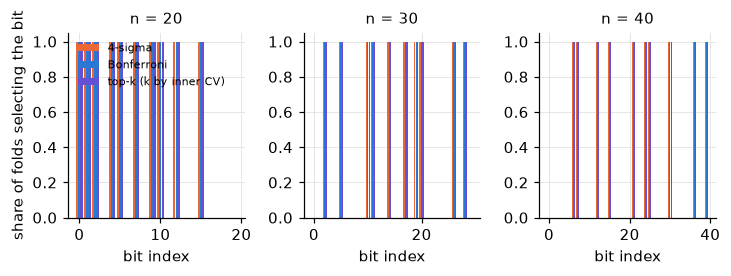

saved exp_figures/fig_selected_bits.pdf


In [16]:
def jaccard_mean(sets):
    sets = [set(s) for s in sets]; v = [len(a & b) / max(len(a | b), 1) for a, b in itertools.combinations(sets, 2)]
    return float(np.mean(v)) if v else float("nan")


def rule_best(n, rule, fam="rf"):
    return [g for g in groups(n) if g["key"] == (fam, f"sel:{rule}", fam)][0]["best"]


tab = []
for n in NS:
    top_gen = top_generic(n)
    for rule in RULES:
        for fam in ("rf", "lookup"):
            b = rule_best(n, rule, fam); nsel = [p["n_sel"] for p in b["post"]]; gz = [p["gate_z"] for p in b["post"]]
            pr = paired(b["folds"], top_gen["best"]["folds"]); ks = [p["k"] for p in b["post"]]
            tab.append([n, f"{NAME[fam]}, {RULE_NAME[rule]}", f"{b['mean']:.3f} ± {b['sd']:.3f}", f"{np.mean(nsel):.1f}", (f"{ks}" if rule == "topk" else ""),
                        f"{jaccard_mean([p['bits'] for p in b['post']]):.2f} (noise: {('n/a' if rule == 'bonf' else format(NULL_STAB[n]['orig' if rule == 'orig' else 'topk8'], '.2f'))})", f"{np.mean(gz):.1f}",
                        f"{pr['mean']:+.3f} [{pr['lo']:+.3f}, {pr['hi']:+.3f}]"])
display(Markdown("**Each rule: predictive accuracy and selection stability.**\n\n" + md_table(["n", "pipeline (best forest setting by CV)", "CV accuracy (mean ± sd over folds)", "bits selected (mean)", "k chosen per fold",
    "stability: fold-to-fold Jaccard (shuffled-label baseline)", "gate z (mean)", "paired difference to the best generic model, mean [95% interval]"], tab)))

# ---- rule against rule, same folds
tab = []
for n in NS:
    for a, b_ in (("topk", "orig"), ("topk", "bonf"), ("orig", "bonf")):
        pr = paired(rule_best(n, a)["folds"], rule_best(n, b_)["folds"])
        tab.append([n, f"{RULE_NAME[a]} minus {RULE_NAME[b_]}", f"{pr['mean']:+.3f} [{pr['lo']:+.3f}, {pr['hi']:+.3f}]", f"{pr['wins']} of {pr['k']}",
                    "distinguishable" if (pr["lo"] > 0 or pr["hi"] < 0) else "not distinguishable"])
display(Markdown("**Rule against rule** (random forest on the selected bits, paired over the same folds; Nadeau–Bengio 95% interval).\n\n" + md_table(
    ["n", "difference", "mean [95% interval]", "folds where the first is better", "verdict"], tab)))

fig, axes = plt.subplots(1, 3, figsize=(6.75, 2.6))
for ax, n in zip(axes, NS):
    for j, rule in enumerate(RULES):
        b = rule_best(n, rule); freq = np.zeros(n)
        for p in b["post"]:
            freq[p["bits"]] += 1 / len(b["post"])
        ax.bar(np.arange(n) + (j - 1) * 0.27, freq, 0.26, color=RULE_COL[rule], label=RULE_NAME[rule])
    ax.set_title(f"n = {n}"); ax.set_xlabel("bit index"); ax.set_ylim(0, 1.05)
axes[0].set_ylabel("share of folds selecting the bit"); axes[0].legend(loc="upper left", fontsize=7)
fig.tight_layout(); savefig(fig, "fig_selected_bits")

### 6.1 Shuffled-label controls of the whole pipeline

Each rule's best configuration is run through the same CV with the **training labels shuffled** (the held-out fold keeps its true labels), selection and, for top-k, the inner CV included. If there is no leakage, accuracy must be at chance. The number of bits selected and their overlap between folds show how much each rule invents when there is nothing to find: a rule that fills its quota from noise will show the same count as on real data but a low overlap.

In [17]:
tab = []
for n in NS:
    for rule in RULES:
        b = rule_best(n, rule); fam, cond, p = "rf", f"sel:{rule}", b["params"]
        r = run(FIN, f"shuffle_rule|{n}|{rule}", lambda: cv_eval(lambda: make_estimator(fam, p, cond), n, fam=fam, shuffle_labels=True, post=sel_post), quiet=True,
                exp="CONTROL", n=n, family=fam, cond=cond, sub="shuffled labels")
        tab.append([n, RULE_NAME[rule], f"{b['mean']:.3f}", f"{r['mean']:.3f} ± {r['sd']:.3f}", f"{np.mean([q['n_sel'] for q in b['post']]):.1f}", f"{np.mean([q['n_sel'] for q in r['post']]):.1f}",
                    f"{jaccard_mean([q['bits'] for q in r['post']]):.2f}", "ok" if abs(r["mean"] - 0.5) < 0.03 else "INVESTIGATE"])
display(Markdown(md_table(["n", "rule", "CV accuracy, real labels", "CV accuracy, shuffled labels", "bits selected, real", "bits selected, shuffled", "fold-to-fold overlap, shuffled", "shuffled accuracy within 0.03 of chance?"], tab)))

| n | rule | CV accuracy, real labels | CV accuracy, shuffled labels | bits selected, real | bits selected, shuffled | fold-to-fold overlap, shuffled | shuffled accuracy within 0.03 of chance? |
|---|---|---|---|---|---|---|---|
| 20 | 4-sigma | 0.958 | 0.503 ± 0.005 | 10.0 | 2.0 | 0.03 | ok |
| 20 | Bonferroni | 0.958 | 0.504 ± 0.000 | 10.0 | 0.0 | 0.00 | ok |
| 20 | top-k (k by inner CV) | 0.958 | 0.503 ± 0.008 | 10.0 | 9.6 | 0.31 | ok |
| 30 | 4-sigma | 0.962 | 0.486 ± 0.039 | 10.0 | 2.0 | 0.07 | ok |
| 30 | Bonferroni | 0.962 | 0.501 ± 0.000 | 10.0 | 0.0 | 0.00 | ok |
| 30 | top-k (k by inner CV) | 0.962 | 0.486 ± 0.023 | 10.0 | 9.2 | 0.19 | ok |
| 40 | 4-sigma | 0.960 | 0.498 ± 0.008 | 10.0 | 2.0 | 0.03 | ok |
| 40 | Bonferroni | 0.960 | 0.502 ± 0.000 | 10.0 | 0.0 | 0.00 | ok |
| 40 | top-k (k by inner CV) | 0.960 | 0.501 ± 0.007 | 10.0 | 8.0 | 0.11 | ok |

## 7. MLP on the selected bits (conditional)

The forest is the first second-stage classifier. An MLP on the selected bits is worth running only if (a) the forest on selected bits is clearly better than the best generic model (the paired interval excludes 0) **and** (b) it is still short of the working target of 0.93, so that a different classifier on the same bits could plausibly add something. The cell prints that assessment; `RUN_MLP_ON_SELECTED` (first code cell) decides whether the MLP is run.

In [18]:
def best_sel_rf(n):
    return max((g for g in groups(n) if g["key"][1].startswith("sel") and g["key"][0] == "rf"), key=lambda g: g["best"]["mean"])


MLP_SEL_JUSTIFIED = {}
for n in NS:
    g, top_gen = best_sel_rf(n), top_generic(n); pr = paired(g["best"]["folds"], top_gen["best"]["folds"])
    MLP_SEL_JUSTIFIED[n] = (pr["lo"] > 0) and g["best"]["mean"] < 0.93
    print(f"n={n}: best selected-bits forest {g['best']['mean']:.3f} ({CONDNAME[g['key'][1]]}); paired advantage over {NAME[top_gen['key'][0]]} "
          f"{pr['mean']:+.3f} [{pr['lo']:+.3f}, {pr['hi']:+.3f}]  ->  MLP on selected bits {'justified' if MLP_SEL_JUSTIFIED[n] else 'not justified'}")
if RUN_MLP_ON_SELECTED:
    for n in NS:
        cond = best_sel_rf(n)["key"][1]
        for p in MLP_GRID:
            cv_config(n, "MLPSEL", "mlp", cond, "mlp", p, post=sel_post)
else:
    print("\nRUN_MLP_ON_SELECTED is False: the MLP on selected bits is not run.")

n=20: best selected-bits forest 0.958 (selected bits (4-sigma rule)); paired advantage over MLP +0.072 [+0.045, +0.099]  ->  MLP on selected bits not justified
n=30: best selected-bits forest 0.962 (selected bits (4-sigma rule)); paired advantage over MLP +0.108 [-0.001, +0.217]  ->  MLP on selected bits not justified
n=40: best selected-bits forest 0.960 (selected bits (4-sigma rule)); paired advantage over MLP +0.024 [+0.020, +0.029]  ->  MLP on selected bits not justified

RUN_MLP_ON_SELECTED is False: the MLP on selected bits is not run.


## 8. Paired comparison and the choice of the final pipeline

All candidates were scored on the **same folds**, so they are compared fold by fold. For each candidate we report its paired difference to the leader with a 95 % interval from the Nadeau–Bengio corrected standard error (the five folds share most of their training rows, so the naive standard error would make differences look more certain than they are). A candidate whose interval contains 0 is **not distinguishable** from the leader on this evidence. No fixed percentage-point threshold is used.

**Choice rule (stated before looking at the locked test).** The final pipeline for each n is the candidate with the highest CV mean, excluding the paper baseline (a reference). Which selection rule wins is decided by this comparison, not by statistical conservatism. Tied candidates are listed; exact ties (identical fold scores) go to all-bits models first, then to the Bonferroni rule. The CV mean of the winner is slightly optimistic because it is the maximum over many noisy means; the locked test (§10) is the unbiased check.

**n = 20**

| rank | candidate (best setting by CV) | CV accuracy (mean ± sd over folds) | train | paired difference to leader [95% interval] | folds where it beats the leader | verdict |
|---|---|---|---|---|---|---|
| 1 | random forest on selected bits (4-sigma rule) | 0.958 ± 0.006 | 0.960 |  |  | leader |
| 2 | random forest on selected bits (top-k rule) | 0.958 ± 0.006 | 0.960 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 3 | random forest on selected bits (Bonferroni rule) | 0.958 ± 0.006 | 0.960 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 4 | lookup table on selected bits (4-sigma rule) | 0.958 ± 0.006 | 0.960 | -0.000 [-0.003, +0.002] | 1 of 5 | not distinguishable |
| 5 | lookup table on selected bits (top-k rule) | 0.958 ± 0.006 | 0.960 | -0.000 [-0.003, +0.002] | 1 of 5 | not distinguishable |
| 6 | lookup table on selected bits (Bonferroni rule) | 0.958 ± 0.006 | 0.960 | -0.000 [-0.003, +0.002] | 1 of 5 | not distinguishable |
| 7 | MLP | 0.886 ± 0.014 | 0.989 | -0.072 [-0.099, -0.045] | 0 of 5 | worse |
| 8 | random forest | 0.824 ± 0.023 | 0.981 | -0.134 [-0.184, -0.085] | 0 of 5 | worse |
| ref | paper baseline (quadratic LR), degree 2 | 0.544 ± 0.010 | 0.592 | -0.414 [-0.424, -0.404] | 0 of 5 | worse |

n=20: selected random forest on selected bits (4-sigma rule)  {"max_features": "sqrt", "msl": 1};  not distinguishable from it: 5 of 19 other candidates (random forest on selected bits (top-k rule); random forest on selected bits (Bonferroni rule); lookup table on selected bits (4-sigma rule); lookup table on selected bits (top-k rule)...)


**n = 30**

| rank | candidate (best setting by CV) | CV accuracy (mean ± sd over folds) | train | paired difference to leader [95% interval] | folds where it beats the leader | verdict |
|---|---|---|---|---|---|---|
| 1 | random forest on selected bits (4-sigma rule) | 0.962 ± 0.002 | 0.962 |  |  | leader |
| 2 | lookup table on selected bits (4-sigma rule) | 0.962 ± 0.002 | 0.962 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 3 | random forest on selected bits (top-k rule) | 0.962 ± 0.002 | 0.962 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 4 | lookup table on selected bits (top-k rule) | 0.962 ± 0.002 | 0.962 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 5 | random forest on selected bits (Bonferroni rule) | 0.962 ± 0.002 | 0.962 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 6 | lookup table on selected bits (Bonferroni rule) | 0.962 ± 0.002 | 0.962 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 7 | MLP | 0.854 ± 0.057 | 0.980 | -0.108 [-0.217, +0.001] | 0 of 5 | not distinguishable |
| 8 | random forest | 0.784 ± 0.028 | 0.999 | -0.178 [-0.232, -0.124] | 0 of 5 | worse |
| ref | paper baseline (quadratic LR), degree 2 | 0.532 ± 0.011 | 0.596 | -0.430 [-0.456, -0.404] | 0 of 5 | worse |

n=30: selected random forest on selected bits (4-sigma rule)  {"max_features": "sqrt", "msl": 1};  not distinguishable from it: 6 of 17 other candidates (lookup table on selected bits (4-sigma rule); random forest on selected bits (top-k rule); lookup table on selected bits (top-k rule); random forest on selected bits (Bonferroni rule)...)


**n = 40**

| rank | candidate (best setting by CV) | CV accuracy (mean ± sd over folds) | train | paired difference to leader [95% interval] | folds where it beats the leader | verdict |
|---|---|---|---|---|---|---|
| 1 | random forest on selected bits (4-sigma rule) | 0.960 ± 0.002 | 0.960 |  |  | leader |
| 2 | lookup table on selected bits (4-sigma rule) | 0.960 ± 0.002 | 0.960 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 3 | random forest on selected bits (top-k rule) | 0.960 ± 0.002 | 0.960 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 4 | lookup table on selected bits (top-k rule) | 0.960 ± 0.002 | 0.960 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 5 | random forest on selected bits (Bonferroni rule) | 0.960 ± 0.002 | 0.960 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 6 | lookup table on selected bits (Bonferroni rule) | 0.960 ± 0.002 | 0.960 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 7 | MLP | 0.936 ± 0.004 | 0.994 | -0.024 [-0.029, -0.020] | 0 of 5 | worse |
| 8 | random forest | 0.786 ± 0.024 | 1.000 | -0.174 [-0.221, -0.127] | 0 of 5 | worse |
| ref | paper baseline (quadratic LR), degree 2 | 0.531 ± 0.003 | 0.600 | -0.430 [-0.436, -0.424] | 0 of 5 | worse |

n=40: selected random forest on selected bits (4-sigma rule)  {"max_features": "sqrt", "msl": 1};  not distinguishable from it: 5 of 15 other candidates (lookup table on selected bits (4-sigma rule); random forest on selected bits (top-k rule); lookup table on selected bits (top-k rule); random forest on selected bits (Bonferroni rule)...)


C:\Users\Photon\AppData\Local\Temp\ipykernel_145948\790375605.py:22: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(f"{FIG}/{name}.{ext}")
C:\Users\Photon\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


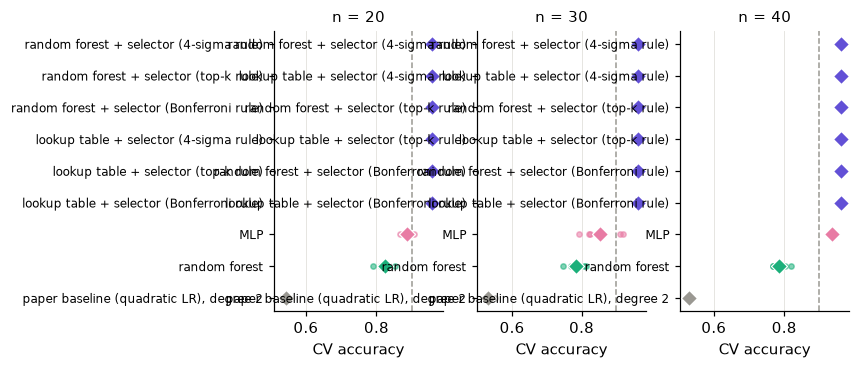

saved exp_figures/fig_cv_overview.pdf


In [19]:
FINAL, TOPN = {}, 8
for n in NS:
    gs = groups(n); cands = [g for g in gs if g["key"][0] != "paper"]; top = cands[0]; FINAL[n] = top
    tab = []
    for i, g in enumerate(cands[:TOPN] + [g for g in gs if g["key"][0] == "paper"]):
        b = g["best"]; pr = paired(b["folds"], top["best"]["folds"])
        verdict = "leader" if g is top else ("not distinguishable" if pr["hi"] >= 0 else "worse")
        tab.append([i + 1 if g["key"][0] != "paper" else "ref", kname(g["key"]), f"{b['mean']:.3f} ± {b['sd']:.3f}", f"{b['train']:.3f}",
                    "" if g is top else f"{pr['mean']:+.3f} [{pr['lo']:+.3f}, {pr['hi']:+.3f}]", "" if g is top else f"{pr['wins']} of {pr['k']}", verdict])
    display(Markdown(f"**n = {n}**\n\n" + md_table(["rank", "candidate (best setting by CV)", "CV accuracy (mean ± sd over folds)", "train", "paired difference to leader [95% interval]",
        "folds where it beats the leader", "verdict"], tab)))
    tied = [kname(g["key"]) for g in cands[1:] if paired(g["best"]["folds"], top["best"]["folds"])["hi"] >= 0]
    print(f"n={n}: selected {kname(top['key'])}  {json.dumps(top['best']['params'])};  not distinguishable from it: {len(tied)} of {len(cands) - 1} other candidates" + (f" ({'; '.join(tied[:4])}{'...' if len(tied) > 4 else ''})" if tied else ""))

fig, axes = plt.subplots(1, 3, figsize=(6.75, 3.3), sharey=False, layout="constrained")
for ax, n in zip(axes, NS):
    gs = [g for g in groups(n) if g["key"][0] != "paper"][:TOPN] + [g for g in groups(n) if g["key"][0] == "paper"]
    for i, g in enumerate(gs):
        fam = g["key"][0]; sel = g["key"][1] != "all"; f = g["best"]["folds"]; col = VIOLET if sel else COL[fam]
        ax.scatter(f, [i] * len(f), s=12, color=col, alpha=0.55, zorder=3)
        ax.scatter([g["best"]["mean"]], [i], s=55, color=col, marker="D", edgecolor=(INK if g is FINAL[n] else "white"), linewidth=1.5 if g is FINAL[n] else 0.8, zorder=4)
    ax.axvline(0.9, color=GRAY, ls="--", lw=1); ax.set_yticks(range(len(gs))); ax.set_yticklabels([kname(g["key"]).replace(" on selected bits", " + selector") for g in gs], fontsize=8)
    ax.grid(axis="y", alpha=0); ax.invert_yaxis(); ax.set_title(f"n = {n}"); ax.set_xlabel("CV accuracy")
savefig(fig, "fig_cv_overview")

## 9. Learning curves for the leading candidates

Only the top candidates of §8 (different families or inputs), because a learning curve is a full set of fits. Each point trains on the first `size` rows of a fixed random order of the training folds (so subsets are nested) and scores on the held-out fold; the selector (if the candidate has one) is re-run on every subset, so it never sees more data than the model. The curves use the first folds only (see `LC_FOLDS`), and the last point is the CV result of §8 restricted to the same folds. Hyper-parameters are those chosen in §8; this is a diagnostic of how accuracy depends on data, not a new selection.

In [20]:
LC_CANDS = {}
for n in NS:
    seen, pick = set(), []
    for g in groups(n):
        k2 = g["key"][:2]
        if g["key"][0] == "paper" or k2 in seen:
            continue
        seen.add(k2); pick.append(g)
        if len(pick) == G["LC_TOP"]:
            break
    LC_CANDS[n] = pick
    for g in pick:
        fam, cond, sub = g["key"]; p = g["best"]["params"]
        for size in G["LC_SIZES"]:
            if size >= FOLD_TRAIN[n]:
                continue
            run(LC, f"lc|{n}|{fam}|{cond}|{sub}|{size}", lambda: cv_eval(lambda: make_estimator(fam, p, cond), n, fam=fam, size=size, folds=G["LC_FOLDS"]),
                exp="LC", n=n, family=fam, cond=cond, sub=sub, size=size)
        fr = [g["best"]["folds"][f] for f in G["LC_FOLDS"]]
        run(LC, f"lc|{n}|{fam}|{cond}|{sub}|{FOLD_TRAIN[n]}", lambda: dict(folds=fr, mean=float(np.mean(fr)), sd=float(np.std(fr, ddof=1)), secs=0.0),
            quiet=True, exp="LC", n=n, family=fam, cond=cond, sub=sub, size=FOLD_TRAIN[n])

lc|20|rf|sel:orig|rf|250                                       0.519 ± 0.052  (2.3s)
lc|20|rf|sel:orig|rf|500                                       0.594 ± 0.096  (2.4s)
lc|20|rf|sel:orig|rf|1000                                      0.735 ± 0.016  (2.5s)
lc|20|rf|sel:orig|rf|2000                                      0.860 ± 0.006  (2.6s)
lc|20|rf|sel:orig|rf|4000                                      0.941 ± 0.016  (2.7s)
lc|20|rf|sel:topk|rf|250                                       0.517 ± 0.025  (12.6s)
lc|20|rf|sel:topk|rf|500                                       0.587 ± 0.095  (13.0s)
lc|20|rf|sel:topk|rf|1000                                      0.692 ± 0.007  (13.0s)
lc|20|rf|sel:topk|rf|2000                                      0.860 ± 0.006  (12.7s)
lc|20|rf|sel:topk|rf|4000                                      0.941 ± 0.016  (13.4s)
lc|20|rf|sel:bonf|rf|250                                       0.498 ± 0.005  (0.0s)
lc|20|rf|sel:bonf|rf|500                                    

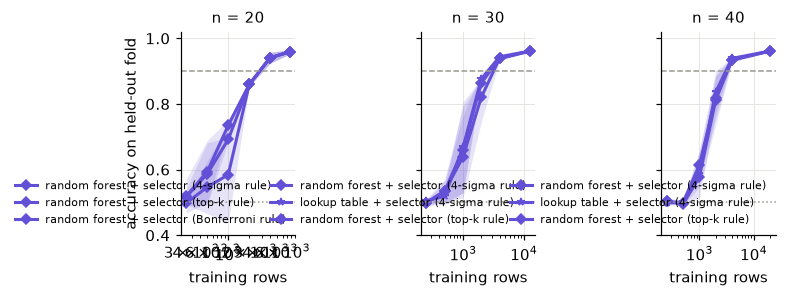

saved exp_figures/fig_learning_curves.pdf


| n | candidate | size 1 | size 2 | size 3 | size 4 | size 5 | size 6 |
|---|---|---|---|---|---|---|---|
| 20 | random forest on selected bits (4-sigma rule) | 0.519 | 0.594 | 0.735 | 0.860 | 0.941 | 0.959 |
| 20 | random forest on selected bits (top-k rule) | 0.517 | 0.587 | 0.692 | 0.860 | 0.941 | 0.959 |
| 20 | random forest on selected bits (Bonferroni rule) | 0.498 | 0.547 | 0.585 | 0.860 | 0.941 | 0.959 |
| 30 | random forest on selected bits (4-sigma rule) | 0.499 | 0.535 | 0.661 | 0.864 | 0.939 | 0.961 |
| 30 | lookup table on selected bits (4-sigma rule) | 0.505 | 0.519 | 0.668 | 0.876 | 0.944 | 0.961 |
| 30 | random forest on selected bits (top-k rule) | 0.498 | 0.535 | 0.639 | 0.820 | 0.939 | 0.961 |
| 40 | random forest on selected bits (4-sigma rule) | 0.503 | 0.499 | 0.614 | 0.819 | 0.934 | 0.962 |
| 40 | lookup table on selected bits (4-sigma rule) | 0.498 | 0.501 | 0.586 | 0.836 | 0.939 | 0.962 |
| 40 | random forest on selected bits (top-k rule) | 0.503 | 0.495 | 0.577 | 0.812 | 0.934 | 0.962 |

Sizes: [250, 500, 1000, 2000, 4000] and the full fold-train set (7680, 12800, 20480 rows for n = 20, 30, 40).

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(6.75, 2.8), sharey=True)
tab = []
for ax, n in zip(axes, NS):
    for g in LC_CANDS[n]:
        fam, cond, sub = g["key"]; rs = sorted(LC.where(n=n, family=fam, cond=cond, sub=sub), key=lambda r: r["size"])
        S, m, s = [r["size"] for r in rs], np.array([r["mean"] for r in rs]), np.array([r["sd"] for r in rs]); col = VIOLET if cond != "all" else COL[fam]
        ax.plot(S, m, marker=MK[fam], color=col, label=kname(g["key"]).replace(" on selected bits", " + selector")); ax.fill_between(S, m - s, m + s, color=col, alpha=0.15, lw=0)
        tab.append([n, kname(g["key"])] + [f"{v:.3f}" for v in m])
    ax.axhline(0.9, color=GRAY, ls="--", lw=1); ax.axhline(0.5, color=GRAY, ls=":", lw=1)
    ax.set_xscale("log"); ax.set_title(f"n = {n}"); ax.set_xlabel("training rows"); ax.set_ylim(0.40, 1.02); ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("accuracy on held-out fold")
fig.tight_layout(); savefig(fig, "fig_learning_curves")
display(Markdown(md_table(["n", "candidate"] + [f"size {i + 1}" for i in range(len(G["LC_SIZES"]) + 1)], tab) + f"\n\nSizes: {G['LC_SIZES']} and the full fold-train set ({', '.join(str(FOLD_TRAIN[n]) for n in NS)} rows for n = 20, 30, 40)."))

## 10. Locked test, controls, hidden predictions, export

**10.1 Locked test, once.** The selected pipeline of §8 is refitted on all dev rows (80 %) and scored once on the locked 20 %. The result is stored; re-running the cell reads it back instead of scoring again.

In [22]:
def locked_score(n):
    key = f"locked|{n}"
    if key in FIN.rows:
        return FIN.rows[key]
    fam, cond, sub = FINAL[n]["key"]; p = FINAL[n]["best"]["params"]; X, B, y = load(n); tr, te = DEV[n], _LOCKED_IDX[n]
    def job():
        t0 = time.time(); est = make_estimator(fam, p, cond).fit(B[tr], y[tr]); a = acc(est, B[te], y[te])
        return dict(mean=a, sd=0.0, secs=round(time.time() - t0, 1), n_test=int(len(te)), train=acc(est, B[tr], y[tr]), half=wilson_half(a, len(te)), cv_mean=FINAL[n]["best"]["mean"],
                    cv_sd=FINAL[n]["best"]["sd"], bits=[int(b) for b in est.cols_] if cond != "all" else None, params=p)
    return run(FIN, key, job, exp="FINAL", n=n, family=fam, cond=cond, sub=sub)


tab = []
for n in NS:
    r = locked_score(n)
    tab.append([n, kname(FINAL[n]["key"]), f"{r['cv_mean']:.3f} ± {r['cv_sd']:.3f}", f"{r['mean']:.3f}", f"[{r['mean'] - r['half']:.3f}, {r['mean'] + r['half']:.3f}]", f"{r['mean'] - r['cv_mean']:+.3f}",
                "yes" if r["mean"] - r["half"] >= 0.90 else "no"])
display(Markdown(md_table(["n", "selected pipeline", "CV (dev, optimistic)", "locked test accuracy", "95% Wilson interval", "test minus CV", "interval above 0.90?"], tab)))

locked|20                                                      0.958 ± 0.000  (1.0s)
locked|30                                                      0.959 ± 0.000  (1.4s)
locked|40                                                      0.959 ± 0.000  (2.7s)


| n | selected pipeline | CV (dev, optimistic) | locked test accuracy | 95% Wilson interval | test minus CV | interval above 0.90? |
|---|---|---|---|---|---|---|
| 20 | random forest on selected bits (4-sigma rule) | 0.958 ± 0.006 | 0.958 | [0.949, 0.966] | -0.001 | yes |
| 30 | random forest on selected bits (4-sigma rule) | 0.962 ± 0.002 | 0.959 | [0.952, 0.965] | -0.003 | yes |
| 40 | random forest on selected bits (4-sigma rule) | 0.960 ± 0.002 | 0.959 | [0.954, 0.964] | -0.002 | yes |

**10.2 Controls.** (a) The selected pipeline is run through the same CV with the **training labels shuffled** (on the first `LC_FOLDS` folds); the whole pipeline, including any selection, must come out near 0.5, otherwise something leaks. (b) The paper's Figure 2 is reproduced on the paper's own split (60/20/20, `random_state=42`, quadratic LR on the raw inputs at 25 / 50 / 100 % of its training split), as a reference only. It is run here, after the locked test, because the paper's test rows overlap ours; nothing is selected from it.

shuffle|20                                                     0.505 ± 0.002  (2.1s)
shuffle|30                                                     0.474 ± 0.051  (2.3s)
shuffle|40                                                     0.499 ± 0.012  (2.5s)


**Shuffled-label control of the selected pipeline**

| n | pipeline | CV accuracy with shuffled training labels | within 0.03 of chance? |
|---|---|---|---|
| 20 | random forest on selected bits (4-sigma rule) | 0.505 ± 0.002 | ok |
| 30 | random forest on selected bits (4-sigma rule) | 0.474 ± 0.051 | ok |
| 40 | random forest on selected bits (4-sigma rule) | 0.499 ± 0.012 | ok |

paperfig2|20|0.25                                              0.522 ± 0.000  (0.4s)
paperfig2|20|0.5                                               0.532 ± 0.000  (0.7s)
paperfig2|20|1.0                                               0.548 ± 0.000  (1.4s)
paperfig2|30|0.25                                              0.519 ± 0.000  (1.3s)
paperfig2|30|0.5                                               0.522 ± 0.000  (2.6s)
paperfig2|30|1.0                                               0.540 ± 0.000  (5.2s)
paperfig2|40|0.25                                              0.517 ± 0.000  (3.6s)
paperfig2|40|0.5                                               0.523 ± 0.000  (7.2s)
paperfig2|40|1.0                                               0.528 ± 0.000  (15.0s)


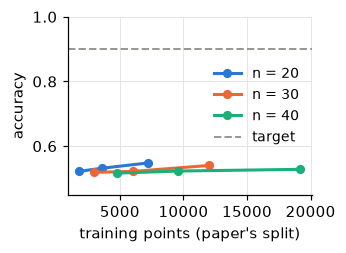

saved exp_figures/fig_paper_figure2_reproduction.pdf


In [23]:
from sklearn.model_selection import train_test_split as _tts
tab = []
for n in NS:
    fam, cond, sub = FINAL[n]["key"]; p = FINAL[n]["best"]["params"]
    r = run(FIN, f"shuffle|{n}", lambda: cv_eval(lambda: make_estimator(fam, p, cond), n, fam=fam, folds=G["LC_FOLDS"], shuffle_labels=True), exp="CONTROL", n=n, family=fam, cond=cond, sub=sub)
    tab.append([n, kname(FINAL[n]["key"]), f"{r['mean']:.3f} ± {r['sd']:.3f}", "ok" if abs(r["mean"] - 0.5) < 0.03 else "INVESTIGATE: possible leakage"])
display(Markdown("**Shuffled-label control of the selected pipeline**\n\n" + md_table(["n", "pipeline", "CV accuracy with shuffled training labels", "within 0.03 of chance?"], tab)))

fig2 = {}
for n in NS:
    X, B, y = load(n)
    Xtr, Xtmp, ytr, ytmp = _tts(X, y, test_size=0.4, random_state=42); Xva, Xte, yva, yte = _tts(Xtmp, ytmp, test_size=0.5, random_state=42)
    fig2[n] = []
    for frac in (0.25, 0.5, 1.0):
        m = int(frac * len(ytr))
        r = run(FIN, f"paperfig2|{n}|{frac}", lambda: (lambda t0, est: dict(mean=acc(est, Xte, yte), sd=0.0, secs=round(time.time() - t0, 1), size=m))(time.time(), PaperBaseline().fit(Xtr[:m], ytr[:m])),
                exp="PAPERFIG2", n=n, family="paper", cond="all", sub=str(frac))
        fig2[n].append((m, r["mean"]))
fig, ax = plt.subplots(figsize=(3.25, 2.4))
for n in NS:
    ax.plot(*zip(*fig2[n]), marker="o", color=N_COL[n], label=f"n = {n}")
ax.axhline(0.9, color=GRAY, ls="--", lw=1.3, label="target"); ax.set_xlabel("training points (paper's split)"); ax.set_ylabel("accuracy"); ax.set_ylim(0.45, 1.0); ax.legend(frameon=False)
fig.tight_layout(); savefig(fig, "fig_paper_figure2_reproduction")

**10.3 Hidden-set predictions.** The selected pipeline is refitted on **all** labelled rows (dev + locked; the locked score above has already been recorded) and applied to the hidden inputs, rounded to bits. The cell checks the format, the class balance, that the hidden inputs look like the labelled ones, and that a second, different good model agrees. It writes `hiddenlabels/y_predicted_{20,30,40}.npy`; `y_predicted_40_adapt.npy` belongs to the LoRA part and is not produced here, so `check_submission.py` will report it missing until that exists.

In [24]:
if WRITE_PREDICTIONS:
    os.makedirs("hiddenlabels", exist_ok=True)
PRED = {}
for n in NS:
    fam, cond, sub = FINAL[n]["key"]; p = FINAL[n]["best"]["params"]; X, B, y = load(n)
    Xh = np.load(f"{DATA}/hidden-kryptonite-{n}-X.npy"); Bh = np.where(Xh > 0, 1.0, -1.0).astype(np.float32)
    est = make_estimator(fam, p, cond).fit(B, y)
    pred = est.predict(Bh).astype(np.int64); PRED[n] = pred
    assert pred.shape == (10_000,) and set(np.unique(pred)) <= {0, 1}, "wrong shape or values"
    assert 0.45 <= pred.mean() <= 0.55, f"suspicious class balance {pred.mean():.3f}"
    assert np.abs(Bh.mean(0) - B.mean(0)).max() < 0.05, "hidden bits do not look like the labelled bits"
    assert np.mean(np.abs(Xh - Bh) < 0.5) > 0.999, "hidden inputs are not clean +-1 bits plus small noise"
    msg = f"n={n}: {kname(FINAL[n]['key'])}, predicted positive rate {pred.mean():.3f}" + (f", bits {est.cols_}" if cond != "all" else "")
    alt = next((g for g in groups(n) if g["key"][:2] != (fam, cond) and g["key"][0] != "paper" and g["best"]["mean"] > 0.9), None)
    if alt:
        p2 = make_estimator(alt["key"][0], alt["best"]["params"], alt["key"][1]).fit(B, y).predict(Bh); agree = float((p2 == pred).mean())
        msg += f"; agreement with {kname(alt['key'])}: {agree:.3f}" + ("  <-- LOW, look at this" if agree < 0.85 else "")
    print(msg)
    if WRITE_PREDICTIONS:
        np.save(f"hiddenlabels/y_predicted_{n}.npy", pred)
if WRITE_PREDICTIONS:
    for n in NS:
        a = np.load(f"hiddenlabels/y_predicted_{n}.npy"); assert a.shape == (10000,) and np.isin(a, [0, 1]).all()
    print("\nwritten and re-checked:", sorted(os.listdir("hiddenlabels")))

n=20: random forest on selected bits (4-sigma rule), predicted positive rate 0.499, bits [0, 1, 2, 4, 5, 7, 9, 10, 12, 15]; agreement with random forest on selected bits (top-k rule): 1.000
n=30: random forest on selected bits (4-sigma rule), predicted positive rate 0.501, bits [2, 5, 10, 11, 14, 17, 19, 20, 26, 28]; agreement with lookup table on selected bits (4-sigma rule): 1.000
n=40: random forest on selected bits (4-sigma rule), predicted positive rate 0.504, bits [6, 7, 12, 15, 21, 24, 25, 30, 36, 39]; agreement with lookup table on selected bits (4-sigma rule): 1.000

written and re-checked: ['y_predicted_20.npy', 'y_predicted_30.npy', 'y_predicted_40.npy']


**10.4 Export and compute log.**

In [25]:
cols = ["exp", "n", "family", "cond", "sub", "size", "mean", "sd", "train", "secs", "params"]
with open(f"{OUT}/all_results.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(cols)
    for st in (CV, LC, FIN):
        for r in st.rows.values():
            w.writerow([json.dumps(r.get(c)) if c == "params" else r.get(c, "") for c in cols])
with open(f"{OUT}/cv_folds.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["n", "family", "cond", "sub", "params"] + [f"fold{i}" for i in range(K)])
    for r in CV.rows.values():
        w.writerow([r["n"], r["family"], r["cond"], r["sub"], json.dumps(r["params"])] + r["folds"])
log = {}
for st in (CV, LC, SYN, FIN):
    for r in st.rows.values():
        log[r["exp"]] = log.get(r["exp"], 0.0) + r.get("secs", 0.0)
display(Markdown("**Compute time recorded per experiment (minutes, sum of per-fit timings; wall-clock is about 4% more)**\n\n" + md_table(["experiment", "minutes"], [[k, f"{v / 60:.1f}"] for k, v in log.items()] + [["total", f"{sum(log.values()) / 60:.1f}"]])))
print("files in", OUT, ":", sorted(os.listdir(OUT)))
print("figures in", FIG, ":", sorted(f for f in os.listdir(FIG) if f.endswith('.pdf')))

**Compute time recorded per experiment (minutes, sum of per-fit timings; wall-clock is about 4% more)**

| experiment | minutes |
|---|---|
| BASE | 3.3 |
| LR | 8.1 |
| TREE | 2.7 |
| KM | 1.7 |
| MLP | 212.3 |
| SEL | 8.3 |
| LC | 4.2 |
| SYN | 1.9 |
| CONTROL | 2.4 |
| FINAL | 0.1 |
| PAPERFIG2 | 0.6 |
| total | 245.6 |

files in exp_results : ['all_results.csv', 'cv_folds.csv', 'cv_results.jsonl', 'final.jsonl', 'learning_curves.jsonl', 'scan_cache.json', 'selector_validation.jsonl']
figures in exp_figures : ['fig_cv_overview.pdf', 'fig_generic.pdf', 'fig_learning_curves.pdf', 'fig_lr_degree.pdf', 'fig_paper_figure2_reproduction.pdf', 'fig_selected_bits.pdf', 'fig_selector_validation.pdf']
